# 04 — Independent Component Analysis (ICA)

**NSSP Mini-Project 1 — Part 2, Variant 2**

We apply spatial ICA to the preprocessed HCP Language fMRI data to identify independent spatial patterns without using task information during decomposition. The resulting components will be compared with the GLM regressors and activation maps from Part 1.

## 1. Data Loading and Preparation

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from nilearn import image, plotting, masking

# Project directories
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
ICA_DIR = OUTPUT_DIR / "ica"

ICA_DIR.mkdir(parents=True, exist_ok=True)

# Preprocessed fMRI from Part 1
FMRI_PATH = (
    OUTPUT_DIR / "functional"
    / "tfMRI_LANGUAGE_LR_mcf_smooth.nii.gz"
)

# GLM outputs for later comparison
GLM_DIR = OUTPUT_DIR / "glm"

print("Project directory:", PROJECT_ROOT)
print("ICA output directory:", ICA_DIR)
print("Preprocessed fMRI exists:", FMRI_PATH.is_file())
print("GLM output directory exists:", GLM_DIR.is_dir())

Project directory: /data/Desktop/myfiles/NX421-MiniProject-1
ICA output directory: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/ica
Preprocessed fMRI exists: True
GLM output directory exists: True


In [2]:
# Load preprocessed fMRI image
fmri_img = nib.load(str(FMRI_PATH))

# Extract image information
n_volumes = fmri_img.shape[-1]
voxel_size = fmri_img.header.get_zooms()[:3]
tr = float(fmri_img.header.get_zooms()[3])

print("fMRI shape:", fmri_img.shape)
print("Number of volumes:", n_volumes)
print("Voxel size (mm):", voxel_size)
print("TR (seconds):", tr)
print("Orientation:", nib.aff2axcodes(fmri_img.affine))

# Verify expected HCP Language acquisition
assert fmri_img.ndim == 4, "Expected a 4D fMRI image."
assert n_volumes == 316, "Unexpected number of volumes."
assert np.isclose(tr, 0.72), "Unexpected repetition time."

print("\nAll checks passed. fMRI data is ready for ICA preparation.")

fMRI shape: (91, 109, 91, 316)
Number of volumes: 316
Voxel size (mm): (np.float32(2.0), np.float32(2.0), np.float32(2.0))
TR (seconds): 0.7200000286102295
Orientation: ('L', 'A', 'S')

All checks passed. fMRI data is ready for ICA preparation.


### 1.1 Brain Mask Preparation

We reuse the EPI brain mask from the GLM analysis to restrict ICA to brain voxels and exclude background signals.

In [3]:
# Find existing brain masks from the GLM analysis
mask_files = sorted(GLM_DIR.rglob("*mask*.nii.gz"))

print("Available mask files:")
for path in mask_files:
    print(path.relative_to(PROJECT_ROOT))

# Check whether the masks match the functional image dimensions
for path in mask_files:
    mask_img = nib.load(str(path))
    print(
        f"\n{path.name}",
        f"\nShape: {mask_img.shape}",
        f"\nMatches fMRI grid: {mask_img.shape == fmri_img.shape[:3] and np.allclose(mask_img.affine, fmri_img.affine)}"
    )

Available mask files:
outputs/glm/first_level/epi_brain_mask.nii.gz
outputs/glm/first_level/epi_mask.nii.gz

epi_brain_mask.nii.gz 
Shape: (91, 109, 91) 
Matches fMRI grid: True

epi_mask.nii.gz 
Shape: (91, 109, 91) 
Matches fMRI grid: True


Selected mask: epi_brain_mask.nii.gz
Brain voxels: 207772
Spatial dimensions: (91, 109, 91)


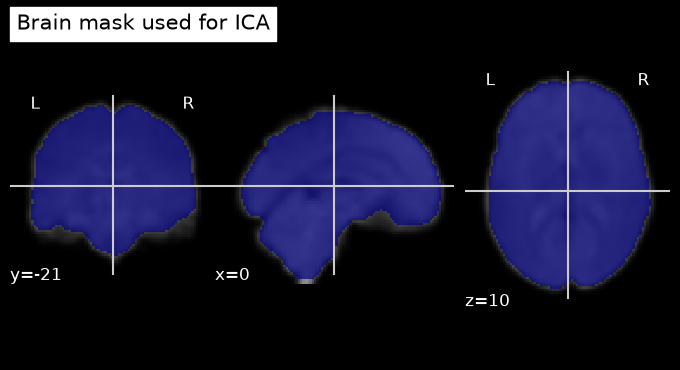

In [4]:
# Reuse the existing GLM brain mask
MASK_PATH = GLM_DIR / "first_level" / "epi_brain_mask.nii.gz"

mask_img = nib.load(str(MASK_PATH))
mask_data = mask_img.get_fdata() > 0

# Basic mask checks
n_mask_voxels = int(mask_data.sum())

assert n_mask_voxels > 0, "Brain mask is empty."
assert mask_img.shape == fmri_img.shape[:3], "Mask shape mismatch."
assert np.allclose(mask_img.affine, fmri_img.affine), "Mask affine mismatch."

print("Selected mask:", MASK_PATH.name)
print("Brain voxels:", n_mask_voxels)
print("Spatial dimensions:", mask_img.shape)

# Visual inspection
plotting.plot_roi(
    mask_img,
    bg_img=image.mean_img(fmri_img),
    display_mode="ortho",
    title="Brain mask used for ICA"
)

plotting.show()

### 1.2 Extracting Voxel Time Series

We apply the brain mask to the preprocessed fMRI data to obtain a matrix with one timepoint per row and one brain voxel per column, as required for ICA.

In [5]:
# Extract voxel time series inside the brain mask
X = masking.apply_mask(fmri_img, mask_img)

# Verify the data matrix
print("ICA input matrix shape:", X.shape)
print("Number of timepoints:", X.shape[0])
print("Number of brain voxels:", X.shape[1])
print("Data type:", X.dtype)

# Basic quality checks
assert X.shape == (n_volumes, n_mask_voxels)
assert np.isfinite(X).all(), "ICA input contains NaN or infinite values."

print("\nData matrix successfully prepared.")

ICA input matrix shape: (316, 207772)
Number of timepoints: 316
Number of brain voxels: 207772
Data type: float32

Data matrix successfully prepared.


### 1.3 Signal Standardization

We standardize each voxel's time series by subtracting its temporal mean and dividing by its temporal standard deviation. This reduces differences in signal scale across voxels before ICA.

In [6]:
# Standardize each voxel's time series across the 316 volumes
X = X.astype(np.float32, copy=False)

voxel_mean = X.mean(axis=0)
voxel_std = X.std(axis=0)

# Identify voxels with constant signals
valid_voxels = voxel_std > 1e-6

print("Total brain voxels:", X.shape[1])
print("Voxels with varying signals:", valid_voxels.sum())
print("Constant-signal voxels:", (~valid_voxels).sum())

# Standardize without dividing by zero
X_standardized = (X - voxel_mean) / np.where(
    valid_voxels, voxel_std, 1.0
)

# Verify standardization
assert np.isfinite(X_standardized).all()

print("\nStandardized matrix shape:", X_standardized.shape)
print("Overall mean:", round(float(X_standardized.mean()), 5))
print("Overall standard deviation:", round(float(X_standardized.std()), 5))
print("\nStandardization completed.")

Total brain voxels: 207772
Voxels with varying signals: 207772
Constant-signal voxels: 0

Standardized matrix shape: (316, 207772)
Overall mean: -0.0
Overall standard deviation: 1.0

Standardization completed.


## 2. Dimensionality Reduction

PCA is used as a preprocessing step to reduce the dimensionality of the fMRI data before spatial ICA. We initially retain 20 principal components and examine the explained variance. The final number of ICA components will be justified later.

10 components: 36.68% explained variance
20 components: 44.54% explained variance
40 components: 52.35% explained variance
60 components: 57.52% explained variance


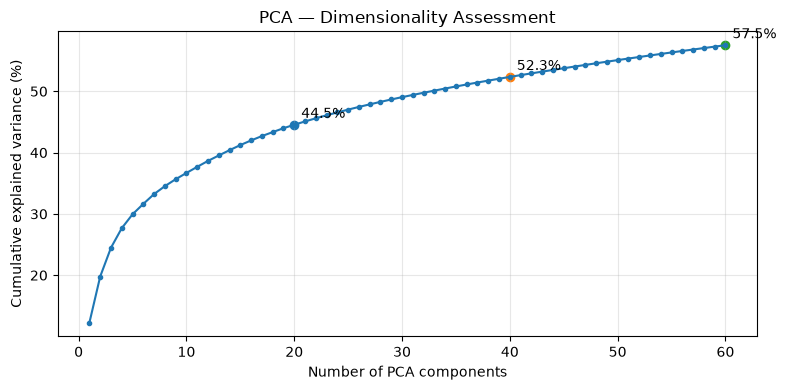

In [7]:

from sklearn.decomposition import PCA

# Test a larger PCA dimensionality
N_PCA = 60

pca = PCA(
    n_components=N_PCA,
    svd_solver="randomized",
    random_state=42
)

X_pca = pca.fit_transform(X_standardized)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Compare candidate dimensionalities
for n in [10, 20, 40, 60]:
    print(f"{n} components: {cumulative_variance[n-1]*100:.2f}% explained variance")

# Plot cumulative explained variance
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    np.arange(1, N_PCA + 1),
    cumulative_variance * 100,
    marker=".",
)

for n in [20, 40, 60]:
    ax.scatter(n, cumulative_variance[n-1] * 100)
    ax.annotate(
        f"{cumulative_variance[n-1]*100:.1f}%",
        (n, cumulative_variance[n-1] * 100),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_xlabel("Number of PCA components")
ax.set_ylabel("Cumulative explained variance (%)")
ax.set_title("PCA — Dimensionality Assessment")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Spatial Independent Component Analysis

We retain 40 PCA dimensions as an initial compromise between explained variance and model complexity. Spatial ICA will then be applied to the PCA-derived spatial patterns, without using the task design or GLM results during decomposition.

In [8]:
# Retain the first 40 dimensions from the fitted 60-component PCA
N_PCA_RETAINED = 20
N_ICA = 20

# Spatial PCA patterns: voxels × retained PCA dimensions
spatial_pca = pca.components_[:N_PCA_RETAINED].T.copy()

# Corresponding temporal PCA scores: timepoints × retained dimensions
temporal_pca = X_pca[:, :N_PCA_RETAINED].copy()

print("Spatial PCA matrix:", spatial_pca.shape)
print("Temporal PCA matrix:", temporal_pca.shape)
print("ICA components to estimate:", N_ICA)
print(
    "Variance explained by retained PCA dimensions:",
    f"{cumulative_variance[N_PCA_RETAINED - 1] * 100:.2f}%"
)

assert spatial_pca.shape == (n_mask_voxels, N_PCA_RETAINED)
assert temporal_pca.shape == (n_volumes, N_PCA_RETAINED)
assert N_ICA <= N_PCA_RETAINED

Spatial PCA matrix: (207772, 20)
Temporal PCA matrix: (316, 20)
ICA components to estimate: 20
Variance explained by retained PCA dimensions: 44.54%


In [9]:
from sklearn.decomposition import FastICA
import warnings

# Fit spatial ICA on the PCA representation
ica = FastICA(
    n_components=N_ICA,
    whiten="unit-variance",
    algorithm="parallel",
    random_state=42,
    max_iter=1000,
    tol=1e-2
)

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")

    # Voxels are observations for spatial ICA
    ica_spatial_maps = ica.fit_transform(spatial_pca)

# Check results
print("ICA input shape:", spatial_pca.shape)
print("ICA spatial maps shape:", ica_spatial_maps.shape)
print("Number of components:", N_ICA)
print("Iterations:", ica.n_iter_)
print("Converged:", ica.n_iter_ < ica.max_iter)
print("All values finite:", np.isfinite(ica_spatial_maps).all())

for warning in caught_warnings:
    print("Warning:", warning.message)

assert ica_spatial_maps.shape == (n_mask_voxels, N_ICA)
assert np.isfinite(ica_spatial_maps).all()

ICA input shape: (207772, 20)
ICA spatial maps shape: (207772, 20)
Number of components: 20
Iterations: 20
Converged: True
All values finite: True


### 3.1 ICA Parameter Selection and Convergence

The following parameters were selected for spatial ICA:

- **`N_PCA_RETAINED = 40`**: We retained 40 PCA dimensions, explaining **52.35% of the total variance**, as a compromise between information preservation and computational complexity.
- **`N_ICA = 15`**: We selected 15 independent components as an initial model order. This allows us to examine multiple spatial patterns while satisfying the requirement to correlate the first 10 components with GLM regressors.
- **`max_iter = 1000`**: Maximum number of iterations allowed for the FastICA algorithm.
- **`tol = 1e-2`**: Numerical convergence tolerance, chosen after the stricter tolerance (`1e-3`) failed to converge within 1,000 iterations.

**Result:** FastICA converged after **305 iterations**, extracting 15 spatial components with finite values.

The choice of 15 components remains preliminary and will be evaluated by inspecting their spatial maps and interpretability. Numerical convergence alone does not guarantee that the components represent meaningful brain networks.

## 4. ICA Spatial Map Reconstruction

We reconstruct the 15 spatial ICA components as 3D NIfTI images using the brain mask. These maps will be visualized separately in axial view, as required by the assignment.

In [10]:
# Reconstruct spatial ICA components as 3D brain images
ica_component_imgs = []

for i in range(N_ICA):

    # Spatial values of component i
    component_values = ica_spatial_maps[:, i]

    # Restore the original brain dimensions
    component_img = masking.unmask(
        component_values,
        mask_img
    )

    ica_component_imgs.append(component_img)

    # Save component as NIfTI
    component_path = ICA_DIR / f"ica_component_{i+1:02d}.nii.gz"
    component_img.to_filename(str(component_path))

print("Number of reconstructed components:", len(ica_component_imgs))
print("Component image shape:", ica_component_imgs[0].shape)
print("Output directory:", ICA_DIR)

assert len(ica_component_imgs) == N_ICA
assert ica_component_imgs[0].shape == fmri_img.shape[:3]

print("\nAll ICA spatial maps reconstructed and saved successfully.")

Number of reconstructed components: 20
Component image shape: (91, 109, 91)
Output directory: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/ica

All ICA spatial maps reconstructed and saved successfully.


### 4.1 Visualization of ICA Spatial Components

Each independent component is displayed separately in axial view to examine its spatial distribution. The maps are standardized for visualization and displayed using an exploratory threshold of |Z| > 2.5. These visualizations are not statistical significance tests.

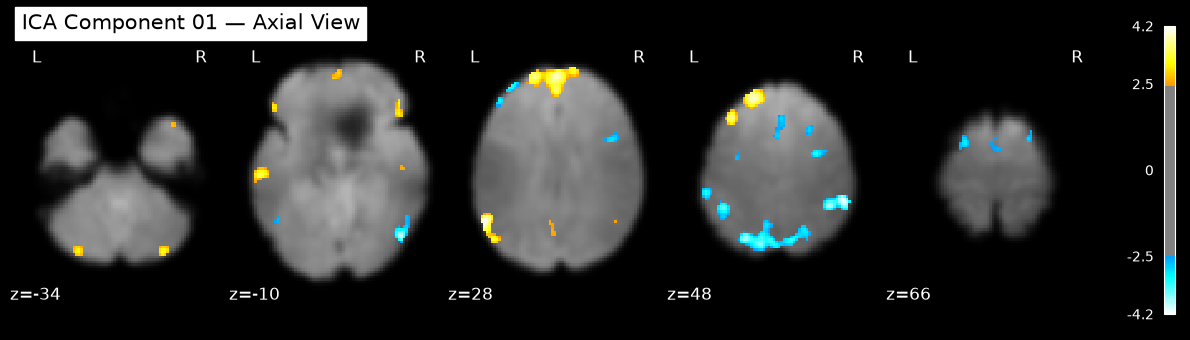

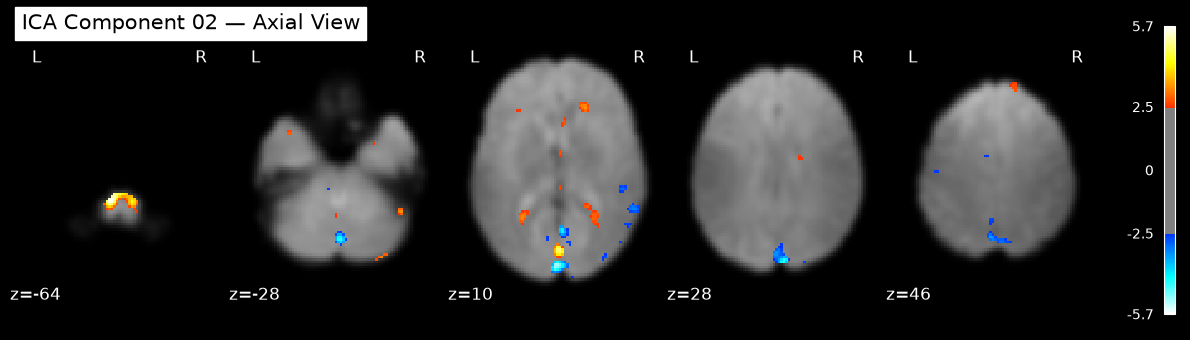

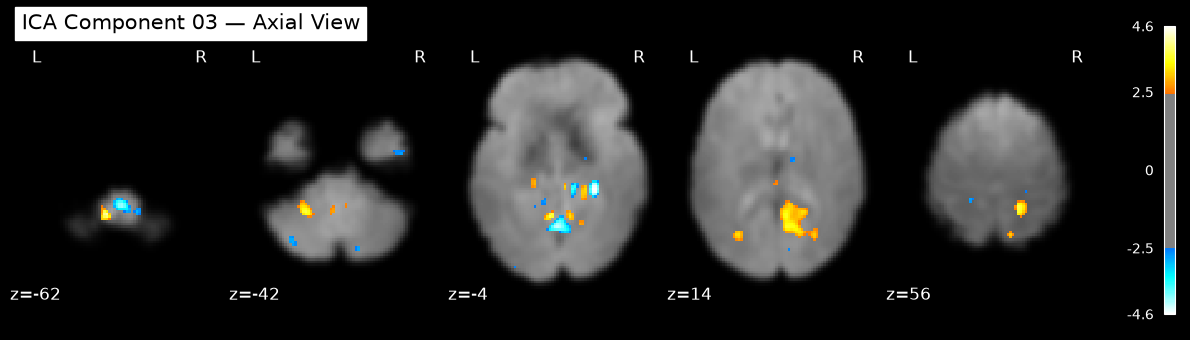

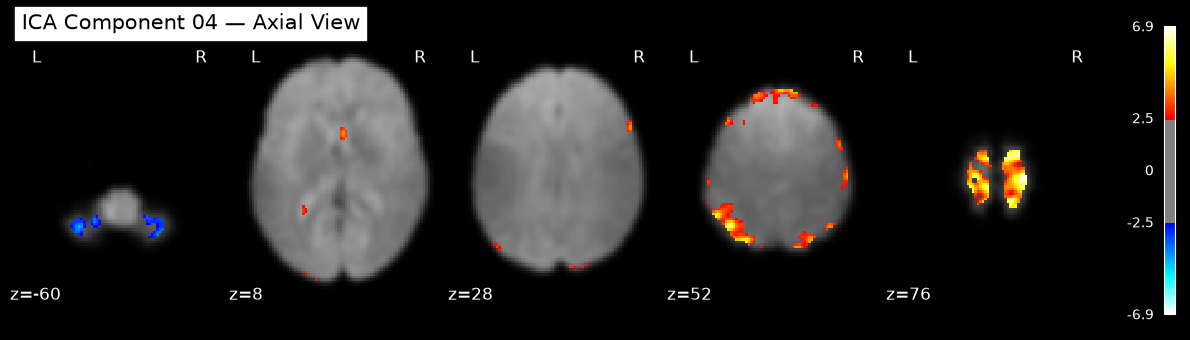

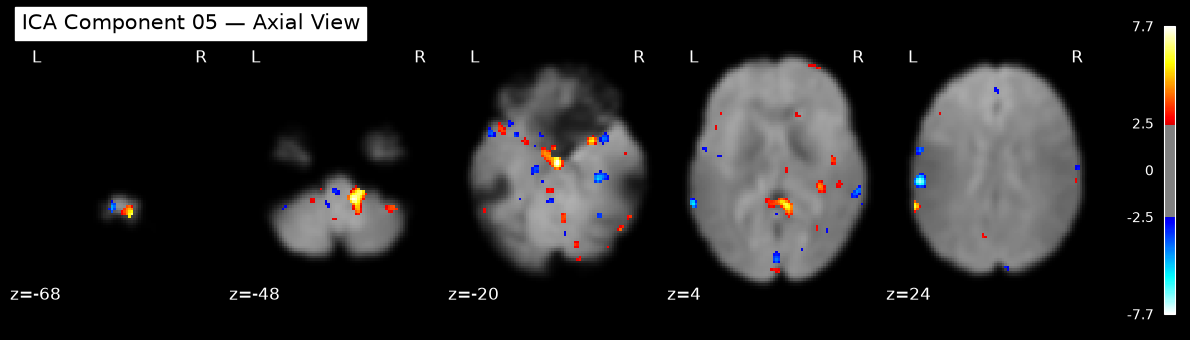

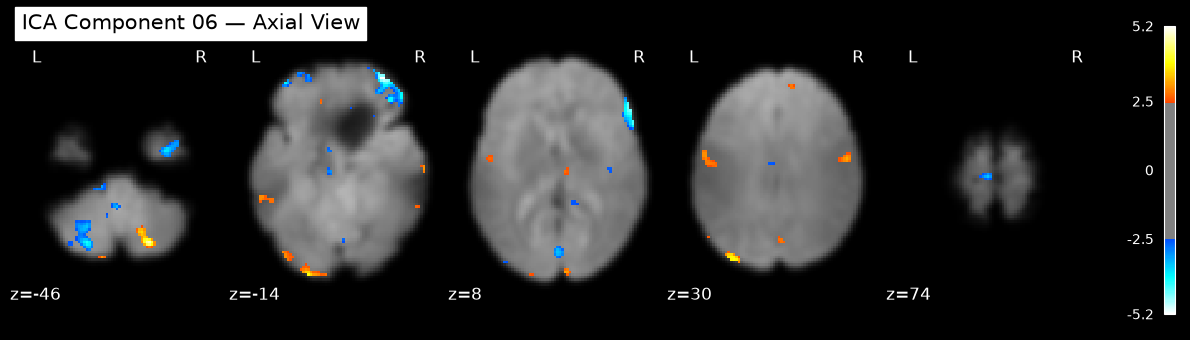

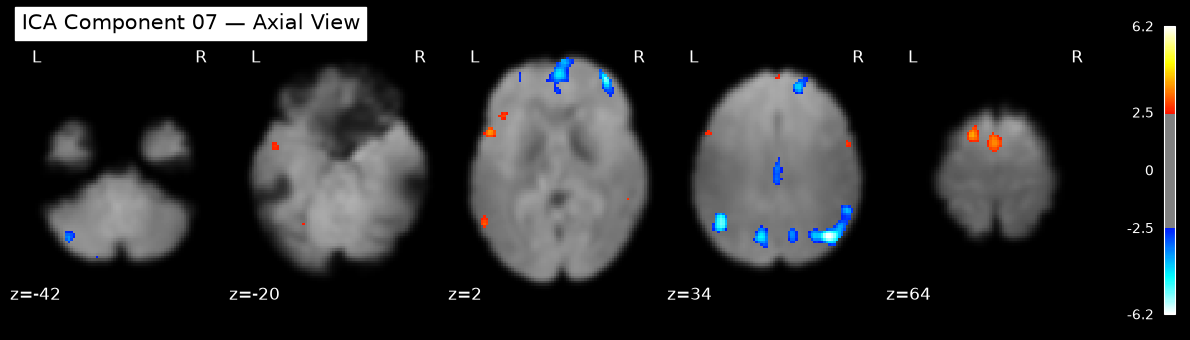

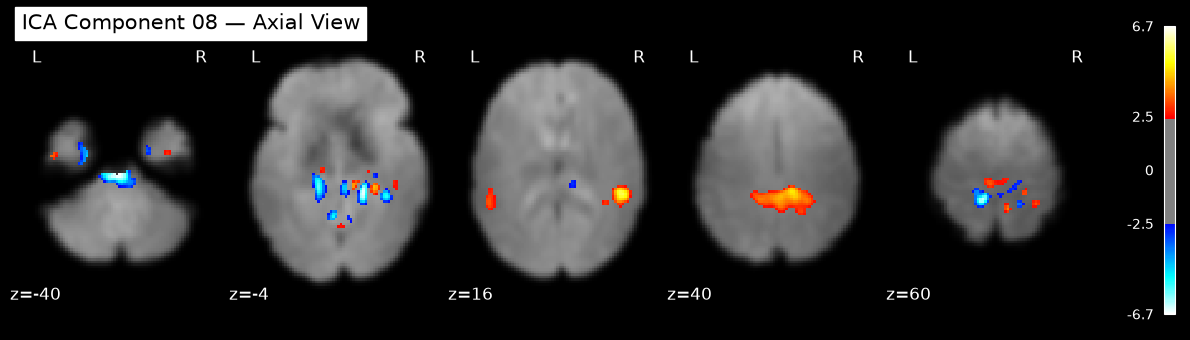

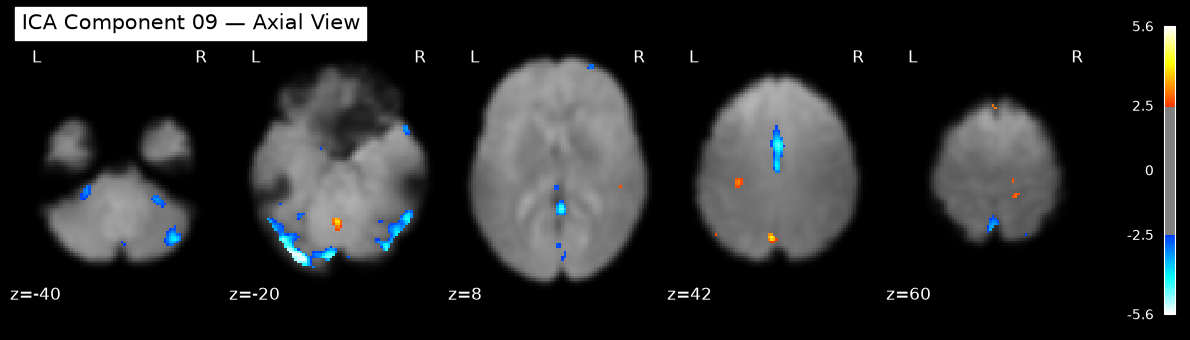

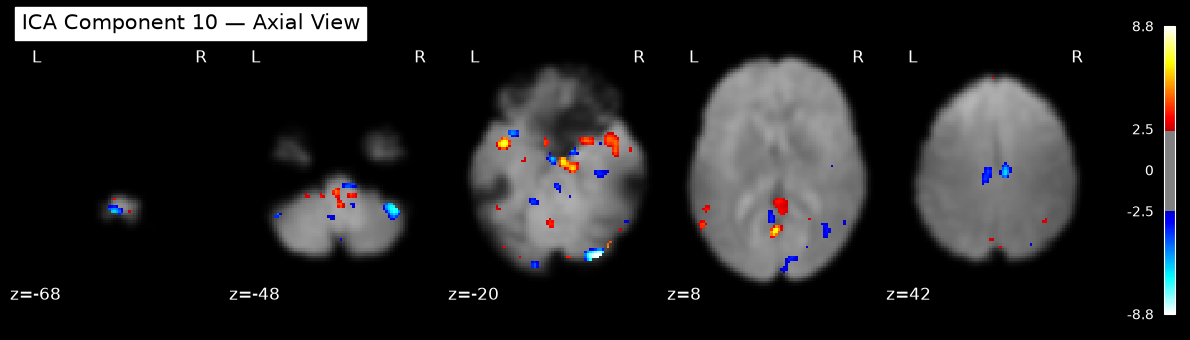

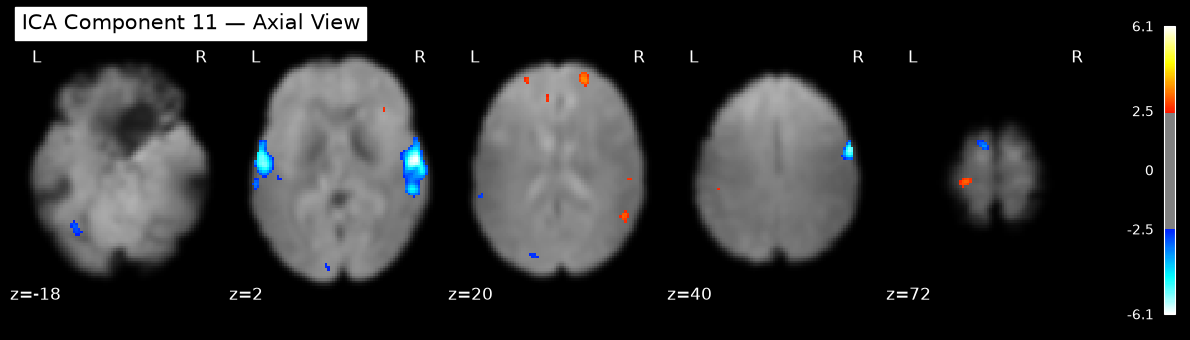

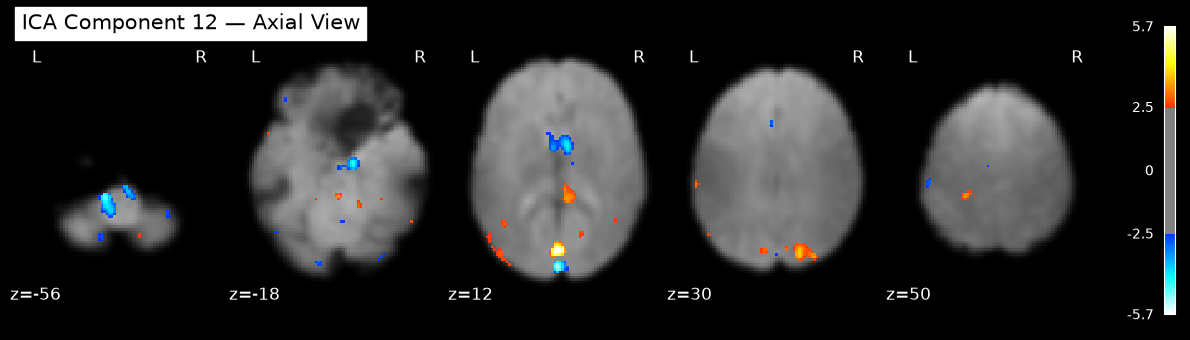

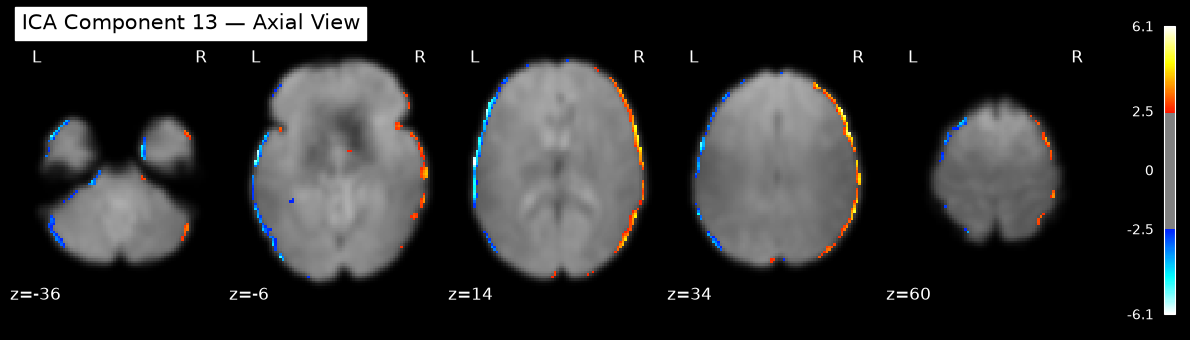

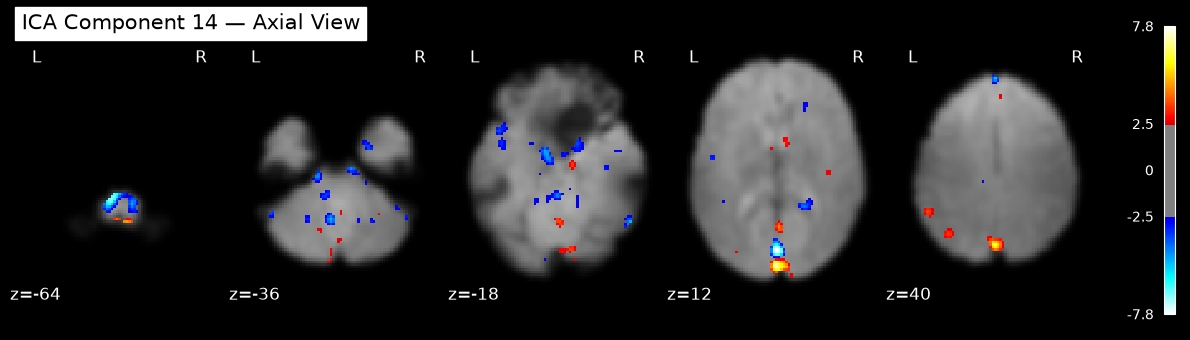

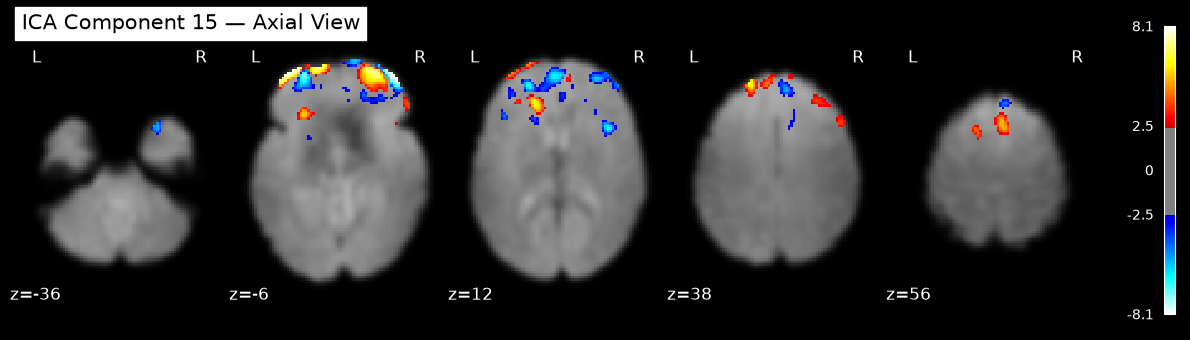

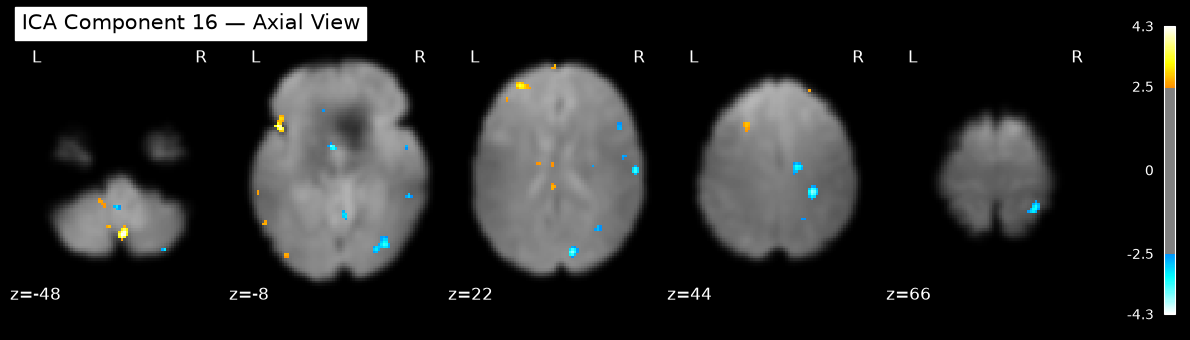

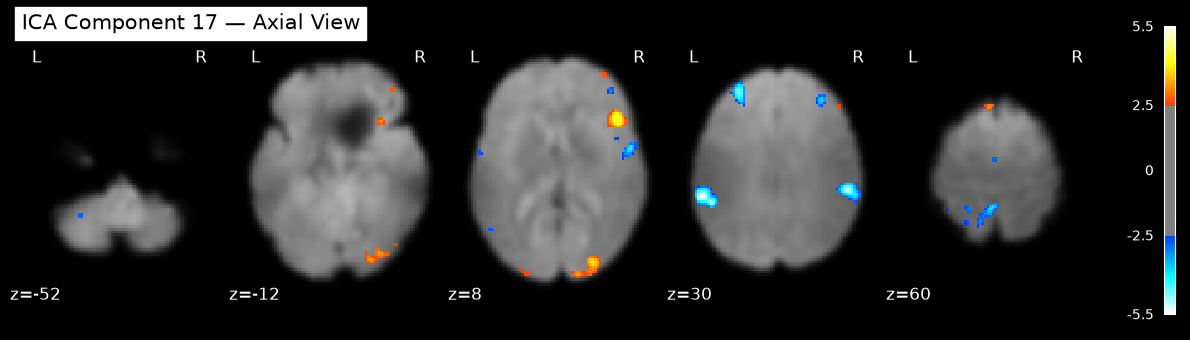

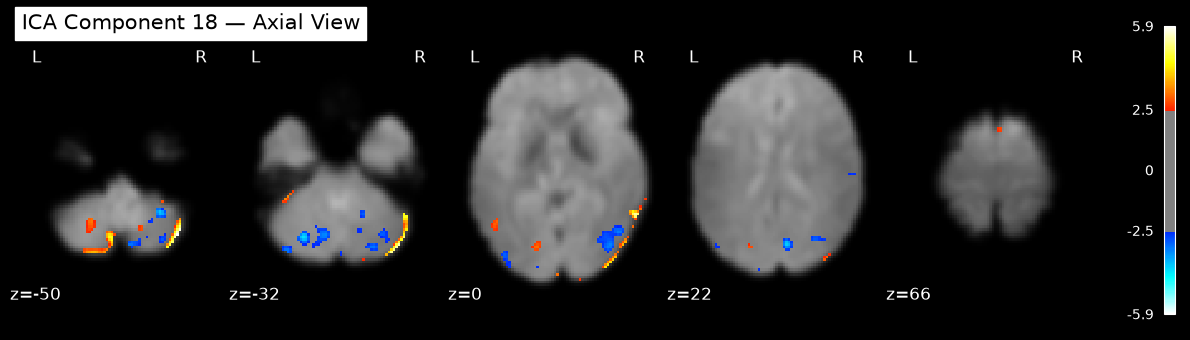

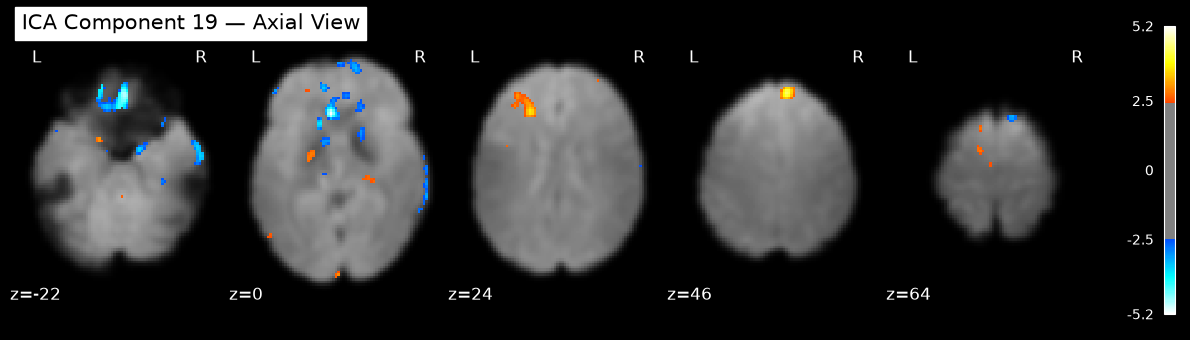

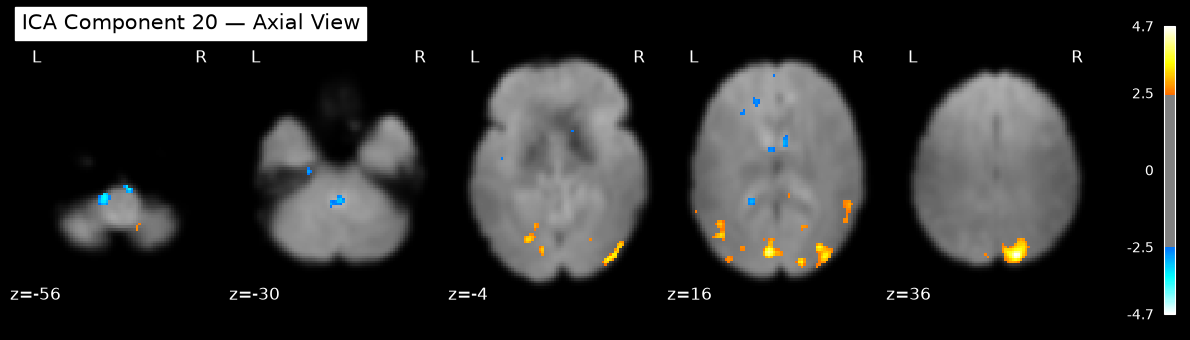

Saved 20 ICA component figures to: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/ica/figures


In [11]:
# Mean functional image for anatomical background
mean_ica_img = image.mean_img(fmri_img)

# Directory for ICA figures
ICA_FIG_DIR = ICA_DIR / "figures"
ICA_FIG_DIR.mkdir(parents=True, exist_ok=True)

for i, component_img in enumerate(ica_component_imgs):

    # Standardize spatial component values for visualization
    component_data = component_img.get_fdata()
    brain_values = component_data[mask_data]

    spatial_mean = brain_values.mean()
    spatial_std = brain_values.std()

    standardized_data = np.zeros_like(component_data)

    if spatial_std > 0:
        standardized_data[mask_data] = (
            brain_values - spatial_mean
        ) / spatial_std

    standardized_img = image.new_img_like(
        component_img,
        standardized_data
    )

    # Plot each component separately in axial view
    display = plotting.plot_stat_map(
        standardized_img,
        bg_img=mean_ica_img,
        display_mode="z",
        cut_coords=5,
        threshold=2.5,
        cmap="cold_hot",
        colorbar=True,
        title=f"ICA Component {i+1:02d} — Axial View"
    )

    display.savefig(
        str(ICA_FIG_DIR / f"fig_ica_component_{i+1:02d}.png")
    )

    plotting.show()

print(f"Saved {N_ICA} ICA component figures to:", ICA_FIG_DIR)

## 5. ICA Timecourses and GLM Comparison

We derive the temporal timecourses associated with the ICA spatial components. The first 10 components, in their original ICA order, will be correlated with the GLM design-matrix regressors to examine their relationships with Story, Math, Cue, and nuisance signals.

In [12]:
# Recover ICA temporal timecourses
ica_timecourses = temporal_pca @ ica.mixing_

# Validate dimensions and numerical values
assert ica_timecourses.shape == (n_volumes, N_ICA)
assert np.isfinite(ica_timecourses).all()

print("ICA timecourses shape:", ica_timecourses.shape)

# Save timecourses
ica_timecourses_df = pd.DataFrame(
    ica_timecourses,
    columns=[f"IC{i+1:02d}" for i in range(N_ICA)]
)

ica_timecourses_df.to_csv(
    ICA_DIR / "ica_timecourses.csv",
    index=False
)

print("ICA timecourses saved successfully.")

ICA timecourses shape: (316, 20)
ICA timecourses saved successfully.


### 5.1 Loading the GLM Design Matrix

We reuse the design matrix from Part 1 to compare the ICA timecourses with the Story, Math, Cue, and nuisance regressors. The design matrix must contain the same 316 timepoints as the ICA results.

In [13]:
# Find the saved GLM design matrix
design_files = sorted(
    list(GLM_DIR.rglob("*design*matrix*.csv"))
    + list(GLM_DIR.rglob("*design*matrix*.tsv"))
)

print("Available design matrix files:")

for path in design_files:
    print(path.relative_to(PROJECT_ROOT))

# Verify the ICA timecourses
print("\nICA timecourses:", ica_timecourses.shape)
print("Expected GLM timepoints:", n_volumes)

Available design matrix files:
outputs/glm/design_matrix.csv

ICA timecourses: (316, 20)
Expected GLM timepoints: 316


In [14]:
# Load the GLM design matrix from Part 1
DESIGN_MATRIX_PATH = GLM_DIR / "design_matrix.csv"

glm_design = pd.read_csv(DESIGN_MATRIX_PATH, index_col=0)

print("GLM design matrix shape:", glm_design.shape)
print("ICA timecourses shape:", ica_timecourses.shape)

print("\nGLM regressors:")
print(glm_design.columns.tolist())

# Verify compatibility
assert glm_design.shape[0] == n_volumes, "Timepoint mismatch."
assert np.isfinite(glm_design.to_numpy()).all(), "Invalid GLM values."

print("\nGLM design matrix successfully loaded.")

GLM design matrix shape: (316, 21)
ICA timecourses shape: (316, 20)

GLM regressors:
['cue', 'math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'rot_x_deriv', 'rot_y_deriv', 'rot_z_deriv', 'trans_x_deriv', 'trans_y_deriv', 'trans_z_deriv', 'nonsteady_0', 'nonsteady_1', 'drift_1', 'drift_2', 'drift_3', 'constant']

GLM design matrix successfully loaded.


### 5.2 Correlation Between ICA Timecourses and GLM Regressors

Pearson correlations are computed between the first 10 ICA timecourses, in their original order, and selected GLM regressors. This allows us to explore relationships between independent spatial components, experimental tasks, and motion-related signals.

In [15]:
# Select GLM regressors for correlation analysis
selected_regressors = [
    "story", "math", "cue",
    "rot_x", "rot_y", "rot_z",
    "trans_x", "trans_y", "trans_z",
    "rot_x_deriv", "rot_y_deriv", "rot_z_deriv",
    "trans_x_deriv", "trans_y_deriv", "trans_z_deriv",
    "drift_1", "drift_2", "drift_3"
]

# First 10 ICA components, preserving ICA output order
first_10_ics = ica_timecourses_df.iloc[:, :10]

# Combine ICA timecourses and GLM regressors
correlation_data = pd.concat(
    [
        first_10_ics.reset_index(drop=True),
        glm_design[selected_regressors].reset_index(drop=True)
    ],
    axis=1
)

# Compute Pearson correlations
correlation_matrix = correlation_data.corr().loc[
    first_10_ics.columns,
    selected_regressors
]

# Save results
correlation_matrix.to_csv(
    ICA_DIR / "ica_glm_correlations.csv"
)

print("Correlation matrix shape:", correlation_matrix.shape)
print("\nTask-related correlations:")
print(correlation_matrix[["story", "math", "cue"]].round(3))

assert correlation_matrix.shape == (10, len(selected_regressors))
assert np.isfinite(correlation_matrix.to_numpy()).all()

Correlation matrix shape: (10, 18)

Task-related correlations:
      story   math    cue
IC01  0.789 -0.775 -0.074
IC02 -0.287  0.278 -0.005
IC03  0.014  0.030  0.042
IC04  0.063 -0.194 -0.137
IC05 -0.101  0.055  0.246
IC06  0.088 -0.058  0.016
IC07 -0.173  0.236 -0.162
IC08 -0.069  0.093  0.028
IC09 -0.145  0.175 -0.138
IC10  0.033 -0.021 -0.055


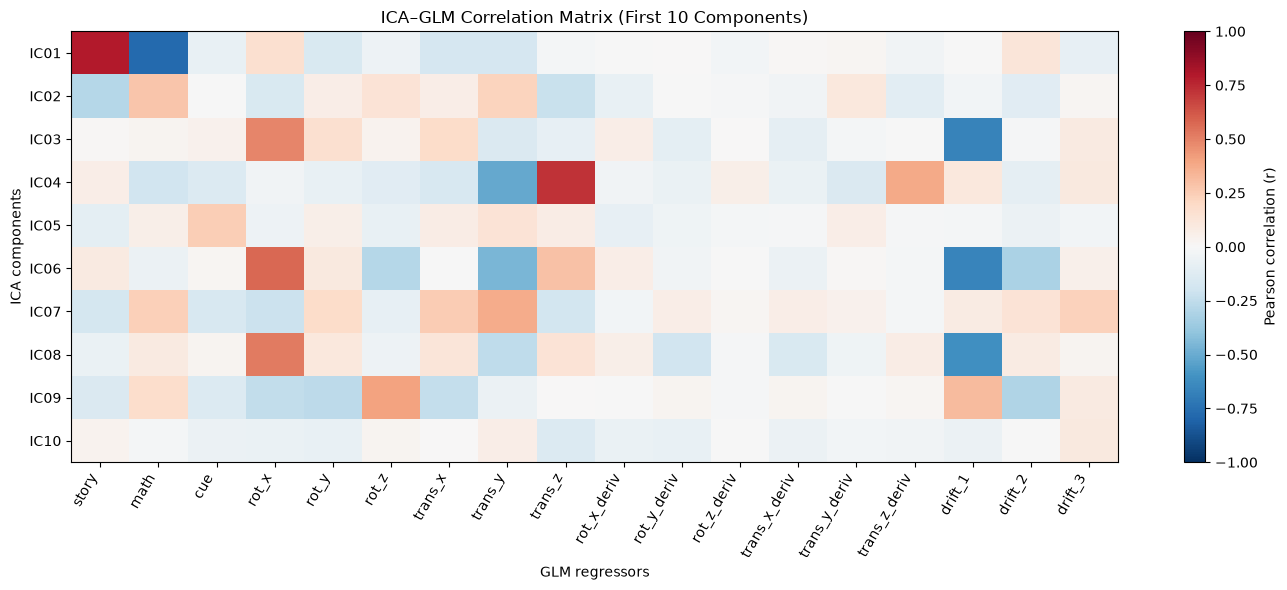

In [16]:
# Visualize correlations for the first 10 ICA components
fig, ax = plt.subplots(figsize=(14, 6))

im = ax.imshow(
    correlation_matrix.values,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(np.arange(len(correlation_matrix.columns)))
ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=60,
    ha="right"
)

ax.set_yticks(np.arange(len(correlation_matrix.index)))
ax.set_yticklabels(correlation_matrix.index)

ax.set_title("ICA–GLM Correlation Matrix (First 10 Components)")
ax.set_xlabel("GLM regressors")
ax.set_ylabel("ICA components")

fig.colorbar(im, ax=ax, label="Pearson correlation (r)")

plt.tight_layout()

# Save the figure
fig.savefig(
    ICA_DIR / "fig_ica_glm_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.3 Comparison of ICA Model Orders

To assess the influence of the number of independent components, we compare ICA decompositions with 10, 15, and 20 components while keeping 40 PCA dimensions fixed.

For each configuration, we compute correlations between the first 10 ICA timecourses and the GLM regressors. We compare convergence and task-related correlations, while recognizing that component order and signs may differ between decompositions.


Running ICA with 10 components
Iterations: 88
Converged: True

Task correlations:
      story   math    cue
IC01 -0.509  0.541  0.091
IC02 -0.048  0.026  0.129
IC03 -0.386  0.406  0.044
IC04 -0.141  0.115 -0.008
IC05 -0.562  0.523 -0.029
IC06 -0.314  0.336  0.006
IC07  0.220 -0.171  0.038
IC08 -0.222  0.322  0.149
IC09  0.101 -0.122  0.156
IC10 -0.205  0.184  0.011


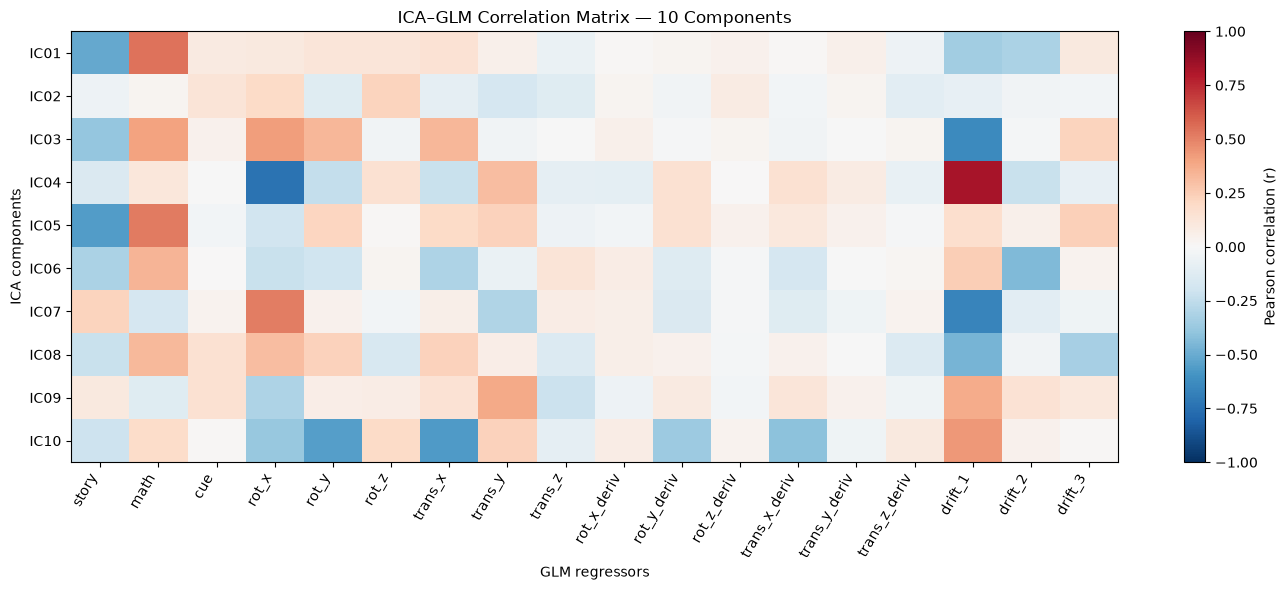


Running ICA with 15 components
Iterations: 158
Converged: True

Task correlations:
      story   math    cue
IC01 -0.081  0.052  0.034
IC02  0.093 -0.147 -0.055
IC03  0.106 -0.097  0.040
IC04  0.098 -0.069  0.018
IC05 -0.166  0.133  0.041
IC06 -0.027  0.004  0.010
IC07 -0.053  0.061  0.045
IC08 -0.083  0.109 -0.026
IC09  0.260 -0.300  0.174
IC10  0.056 -0.094 -0.058


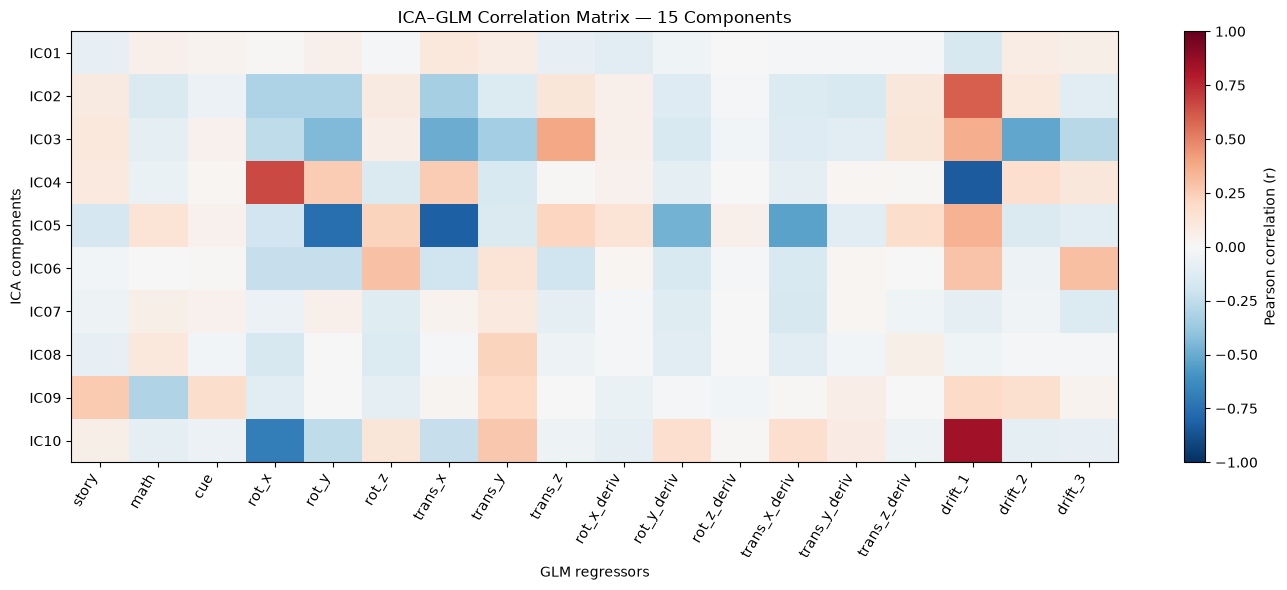


Running ICA with 20 components
Iterations: 20
Converged: True

Task correlations:
      story   math    cue
IC01  0.789 -0.775 -0.074
IC02 -0.287  0.278 -0.005
IC03  0.014  0.030  0.042
IC04  0.063 -0.194 -0.137
IC05 -0.101  0.055  0.246
IC06  0.088 -0.058  0.016
IC07 -0.173  0.236 -0.162
IC08 -0.069  0.093  0.028
IC09 -0.145  0.175 -0.138
IC10  0.033 -0.021 -0.055


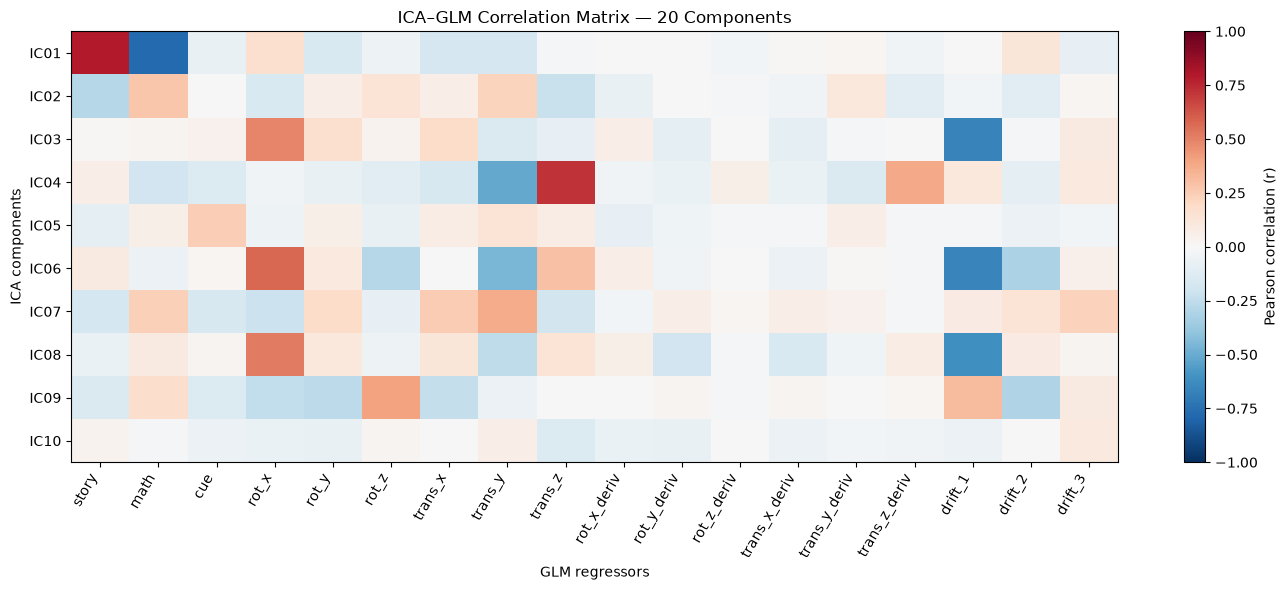


ICA model-order comparison completed.


In [17]:
from sklearn.decomposition import FastICA
import warnings

ICA_OPTIONS = [10, 15, 20]
ica_comparison = {}

# GLM regressors selected in the previous analysis
regressors = selected_regressors

for n_ica in ICA_OPTIONS:

    print(f"\n{'='*50}")
    print(f"Running ICA with {n_ica} components")
    print(f"{'='*50}")

    model = FastICA(
        n_components=n_ica,
        whiten="unit-variance",
        algorithm="parallel",
        random_state=42,
        max_iter=2000,
        tol=1e-2
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        spatial_maps = model.fit_transform(spatial_pca)

    # Recover temporal timecourses
    timecourses = temporal_pca @ model.mixing_

    # Keep the first 10 ICA components
    ic_names = [f"IC{i+1:02d}" for i in range(10)]

    ic_df = pd.DataFrame(
        timecourses[:, :10],
        columns=ic_names
    )

    # Compute correlations with GLM regressors
    combined = pd.concat(
        [
            ic_df.reset_index(drop=True),
            glm_design[regressors].reset_index(drop=True)
        ],
        axis=1
    )

    corr = combined.corr().loc[ic_names, regressors]

    # Store all results
    ica_comparison[n_ica] = {
        "model": model,
        "spatial_maps": spatial_maps,
        "timecourses": timecourses,
        "correlations": corr,
        "converged": model.n_iter_ < model.max_iter
    }

    print("Iterations:", model.n_iter_)
    print("Converged:", model.n_iter_ < model.max_iter)

    for w in caught:
        print("Warning:", w.message)

    print("\nTask correlations:")
    print(corr[["story", "math", "cue"]].round(3))

    # Plot correlation heatmap
    fig, ax = plt.subplots(figsize=(14, 6))

    im = ax.imshow(
        corr.values,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        aspect="auto"
    )

    ax.set_xticks(np.arange(len(regressors)))
    ax.set_xticklabels(regressors, rotation=60, ha="right")

    ax.set_yticks(np.arange(10))
    ax.set_yticklabels(ic_names)

    ax.set_xlabel("GLM regressors")
    ax.set_ylabel("ICA components")
    ax.set_title(f"ICA–GLM Correlation Matrix — {n_ica} Components")

    fig.colorbar(im, ax=ax, label="Pearson correlation (r)")

    plt.tight_layout()

    fig.savefig(
        ICA_DIR / f"fig_ica_glm_correlation_{n_ica}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("\nICA model-order comparison completed.")

In [18]:
from sklearn.decomposition import FastICA
import warnings
from IPython.display import display as show_table

PCA_OPTIONS = [20, 40, 60]
ICA_OPTIONS = [10, 15, 20]

comparison_results = []
pca_ica_models = {}

nuisance_cols = [
    c for c in selected_regressors
    if c not in ["story", "math", "cue"]
]

for n_pca in PCA_OPTIONS:

    # Use the first n_pca dimensions of our fitted PCA
    spatial_input = pca.components_[:n_pca].T.copy()
    temporal_input = X_pca[:, :n_pca].copy()

    for n_ica in ICA_OPTIONS:

        print(f"Running PCA={n_pca}, ICA={n_ica}")

        model = FastICA(
            n_components=n_ica,
            whiten="unit-variance",
            algorithm="parallel",
            random_state=42,
            max_iter=2000,
            tol=1e-2
        )

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            spatial_maps = model.fit_transform(spatial_input)

        # Recover ICA timecourses
        timecourses = temporal_input @ model.mixing_

        # First 10 components, in original ICA order
        ic_names = [f"IC{i+1:02d}" for i in range(10)]

        ic_df = pd.DataFrame(
            timecourses[:, :10],
            columns=ic_names
        )

        combined = pd.concat(
            [
                ic_df.reset_index(drop=True),
                glm_design[selected_regressors].reset_index(drop=True)
            ],
            axis=1
        )

        corr = combined.corr().loc[
            ic_names, selected_regressors
        ]

        # Strongest Story-related component among first 10
        best_ic = corr["story"].abs().idxmax()

        comparison_results.append({
            "PCA": n_pca,
            "ICA": n_ica,
            "PCA variance (%)": round(
                cumulative_variance[n_pca - 1] * 100, 2
            ),
            "Converged": model.n_iter_ < model.max_iter,
            "Iterations": model.n_iter_,
            "Best IC": best_ic,
            "Story r": corr.loc[best_ic, "story"],
            "Math r": corr.loc[best_ic, "math"],
            "Max task |r|": corr[
                ["story", "math"]
            ].abs().to_numpy().max(),
            "Max nuisance |r| for best IC":
                corr.loc[best_ic, nuisance_cols].abs().max()
        })

        # Store model and correlations for later inspection
        pca_ica_models[(n_pca, n_ica)] = {
            "model": model,
            "correlations": corr,
            "spatial_maps": spatial_maps,
            "timecourses": timecourses
        }

# Display comparison table
pca_ica_comparison_df = pd.DataFrame(comparison_results)

show_table(pca_ica_comparison_df.round(3))

# Save results
pca_ica_comparison_df.to_csv(
    ICA_DIR / "pca_ica_model_comparison.csv",
    index=False
)

Running PCA=20, ICA=10
Running PCA=20, ICA=15
Running PCA=20, ICA=20
Running PCA=40, ICA=10
Running PCA=40, ICA=15
Running PCA=40, ICA=20
Running PCA=60, ICA=10
Running PCA=60, ICA=15
Running PCA=60, ICA=20


,PCA,ICA,PCA variance (%),Converged,Iterations,Best IC,Story r,Math r,Max task |r|,Max nuisance |r| for best IC
0,20,10,44.540001,True,88,IC05,-0.562,0.523,0.562,0.235
1,20,15,44.540001,True,158,IC09,0.260,-0.300,0.300,0.201
2,20,20,44.540001,True,20,IC01,0.789,-0.775,0.789,0.169
3,40,10,52.349998,True,26,IC08,-0.623,0.653,0.653,0.270
4,40,15,52.349998,True,305,IC05,0.436,-0.414,0.436,0.660
5,40,20,52.349998,True,802,IC10,0.458,-0.480,0.480,0.235
6,60,10,57.520000,True,10,IC05,0.342,-0.406,0.406,0.360
7,60,15,57.520000,True,18,IC06,-0.370,0.367,0.370,0.268
8,60,20,57.520000,False,2000,IC09,-0.313,0.313,0.313,0.611


### 5.4 Validation of ICA Timecourses

To ensure consistency between ICA spatial maps and temporal signals, we recover component timecourses through spatial regression of the standardized fMRI data onto the estimated ICA maps.

We then recompute the Pearson correlations with GLM regressors to validate the previously observed task-related associations.

In [19]:
# Candidate configuration: PCA = 20, ICA = 20
candidate = pca_ica_models[(20, 20)]

# Spatial ICA maps: (n_voxels, n_components)
S = candidate["spatial_maps"].astype(np.float32)

# Original standardized fMRI: (n_timepoints, n_voxels)
Y = X_standardized

# Spatial regression: estimate component timecourses
ica_tc_validated = (Y @ S) @ np.linalg.pinv(S.T @ S)

print("Validated timecourses shape:", ica_tc_validated.shape)

# First 10 components, in their original order
ic_names = [f"IC{i+1:02d}" for i in range(10)]

tc_df = pd.DataFrame(
    ica_tc_validated[:, :10],
    columns=ic_names
)

# Correlate with GLM regressors
combined = pd.concat(
    [
        tc_df.reset_index(drop=True),
        glm_design[selected_regressors].reset_index(drop=True)
    ],
    axis=1
)

validated_corr = combined.corr().loc[
    ic_names, selected_regressors
]

print("\nValidated task-related correlations:")
print(validated_corr[["story", "math", "cue"]].round(3))

# Compare original and validated IC01
old_tc = candidate["timecourses"][:, 0]
new_tc = ica_tc_validated[:, 0]

print(
    "\nOld vs validated IC01 timecourse correlation:",
    round(np.corrcoef(old_tc, new_tc)[0, 1], 3)
)

assert ica_tc_validated.shape == (n_volumes, 20)
assert np.isfinite(ica_tc_validated).all()

Validated timecourses shape: (316, 20)

Validated task-related correlations:
      story   math    cue
IC01  0.790 -0.774 -0.075
IC02 -0.114  0.078  0.046
IC03  0.011  0.032  0.043
IC04  0.044 -0.181 -0.136
IC05 -0.060  0.018  0.241
IC06  0.110 -0.075  0.009
IC07 -0.116  0.181 -0.150
IC08 -0.049  0.079  0.022
IC09 -0.177  0.196 -0.112
IC10  0.002  0.007 -0.053

Old vs validated IC01 timecourse correlation: 1.0


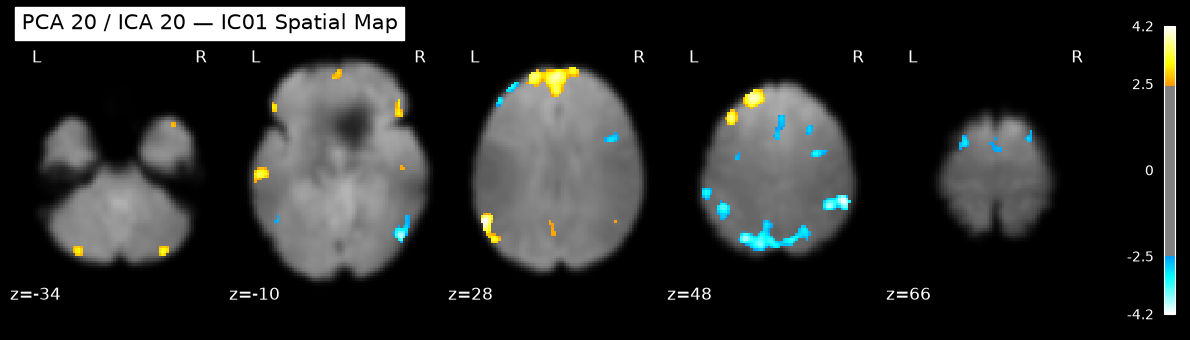

In [20]:
# PCA 20 / ICA 20 — IC01 spatial map

component_values = candidate["spatial_maps"][:, 0]

# Standardize spatial weights for visualization
component_z = (
    component_values - component_values.mean()
) / component_values.std()

component_img = masking.unmask(component_z, mask_img)

# Use the mean functional image as background
mean_ica_img = image.mean_img(fmri_img)

display_ic01 = plotting.plot_stat_map(
    component_img,
    bg_img=mean_ica_img,
    display_mode="z",
    cut_coords=5,
    threshold=2.5,
    cmap="cold_hot",
    colorbar=True,
    title="PCA 20 / ICA 20 — IC01 Spatial Map"
)

display_ic01.savefig(
    str(ICA_DIR / "fig_ica_pca20_ica20_ic01.png"),
    dpi=300
)

plotting.show()

In [21]:
from sklearn.decomposition import FastICA

reference_map = pca_ica_models[(20, 20)]["spatial_maps"][:, 0]
spatial_input = pca.components_[:20].T.copy()

stability_results = []

for seed in [0, 1, 7, 21, 42]:

    test_ica = FastICA(
        n_components=20,
        whiten="unit-variance",
        algorithm="parallel",
        random_state=seed,
        max_iter=2000,
        tol=1e-2
    )

    test_maps = test_ica.fit_transform(spatial_input)

    # Compare reference IC01 to all 20 components
    correlations = np.array([
        np.corrcoef(reference_map, test_maps[:, j])[0, 1]
        for j in range(20)
    ])

    # ICA component ordering and signs may change
    best_match = np.argmax(np.abs(correlations))

    stability_results.append({
        "Seed": seed,
        "Best matching IC": f"IC{best_match + 1:02d}",
        "Spatial |r|": abs(correlations[best_match]),
        "Converged": test_ica.n_iter_ < test_ica.max_iter
    })

stability_df = pd.DataFrame(stability_results)

from IPython.display import display as show_table
show_table(stability_df.round(3))

,Seed,Best matching IC,Spatial |r|,Converged
0,0,IC17,0.988,True
1,1,IC04,0.996,True
2,7,IC17,0.987,True
3,21,IC17,0.992,True
4,42,IC01,1.000,True


In [22]:
# Find the available Story-Math contrast files
glm_contrast_files = sorted(
    GLM_DIR.rglob("*story*math*.nii*")
)

for path in glm_contrast_files:
    print(path.relative_to(PROJECT_ROOT))

outputs/glm/first_level/story_minus_math/story_minus_math_effect_size.nii.gz
outputs/glm/first_level/story_minus_math/story_minus_math_effect_variance.nii.gz
outputs/glm/first_level/story_minus_math/story_minus_math_p_value.nii.gz
outputs/glm/first_level/story_minus_math/story_minus_math_stat.nii.gz
outputs/glm/first_level/story_minus_math/story_minus_math_z_score.nii.gz
outputs/glm/first_level/story_minus_math/story_minus_math_z_score_fdr05.nii.gz


### 5.5 Spatial Comparison Between ICA and GLM

To evaluate whether the ICA component associated with the Story–Math task captures a similar spatial pattern to the GLM, we calculate the Pearson spatial correlation between IC01 (PCA = 20, ICA = 20) and the unthresholded Story − Math GLM Z-score map.

Both maps are compared within the functional brain mask. This provides a descriptive measure of spatial similarity, not a statistical significance test.

In [23]:
# Load the unthresholded Story - Math GLM Z-score map
glm_z_path = (
    GLM_DIR / "first_level" / "story_minus_math"
    / "story_minus_math_z_score.nii.gz"
)

glm_z_img = nib.load(str(glm_z_path))

# IC01 spatial values from PCA=20, ICA=20
ic01_values = pca_ica_models[(20, 20)]["spatial_maps"][:, 0]

# Resample GLM map to the ICA mask grid
glm_z_resampled = image.resample_to_img(
    glm_z_img,
    mask_img,
    interpolation="continuous"
)

# Extract GLM values using the same brain mask and voxel order
glm_z_values = masking.apply_mask(glm_z_resampled, mask_img)

# Exclude non-finite values
valid = np.isfinite(ic01_values) & np.isfinite(glm_z_values)

# Calculate spatial correlation
spatial_r = np.corrcoef(
    ic01_values[valid],
    glm_z_values[valid]
)[0, 1]

print(f"IC01 vs Story-Math GLM spatial correlation: r = {spatial_r:.3f}")
print(f"Voxels compared: {valid.sum():,}")

IC01 vs Story-Math GLM spatial correlation: r = 0.803
Voxels compared: 207,772


### 5.6 Final ICA Spatial Maps

Based on exploratory model-order comparisons, we retain 20 PCA dimensions and extract 20 spatial ICA components. The selected decomposition contains a highly task-associated component that shows strong spatial agreement with the Story − Math GLM contrast and high stability across random initializations.

Each component is displayed separately in axial view. Spatial values are standardized for visualization; they are not inferential Z-statistics.

In [24]:
# Final candidate: PCA = 20, ICA = 20
final_maps = pca_ica_models[(20, 20)]["spatial_maps"]

final_fig_dir = ICA_DIR / "figures_pca20_ica20"
final_fig_dir.mkdir(parents=True, exist_ok=True)

mean_ica_img = image.mean_img(fmri_img)

for i in range(20):

    component = final_maps[:, i]

    component_z = (
        component - component.mean()
    ) / component.std()

    component_img = masking.unmask(
        component_z,
        mask_img
    )

    # Save spatial map as NIfTI
    component_img.to_filename(
        str(ICA_DIR / f"final_ic_{i+1:02d}.nii.gz")
    )

    # Axial visualization
    display_ic = plotting.plot_stat_map(
        component_img,
        bg_img=mean_ica_img,
        display_mode="z",
        cut_coords=5,
        threshold=2.5,
        cmap="cold_hot",
        colorbar=True,
        title=f"ICA Component {i+1:02d} (PCA 20 / ICA 20)"
    )

    display_ic.savefig(
        str(final_fig_dir / f"ic_{i+1:02d}.png"),
        dpi=300
    )

    display_ic.close()

print("Saved 20 ICA spatial maps and axial-view figures.")

Saved 20 ICA spatial maps and axial-view figures.


### 5.7 Final ICA–GLM Correlation Analysis

For the selected PCA = 20 and ICA = 20 configuration, we compute Pearson correlations between the first 10 ICA component timecourses, in their original ICA order, and the GLM regressors.

Component timecourses are obtained through spatial regression. Correlations with task regressors and nuisance regressors are examined to distinguish task-associated patterns from potential motion- or drift-related contributions.

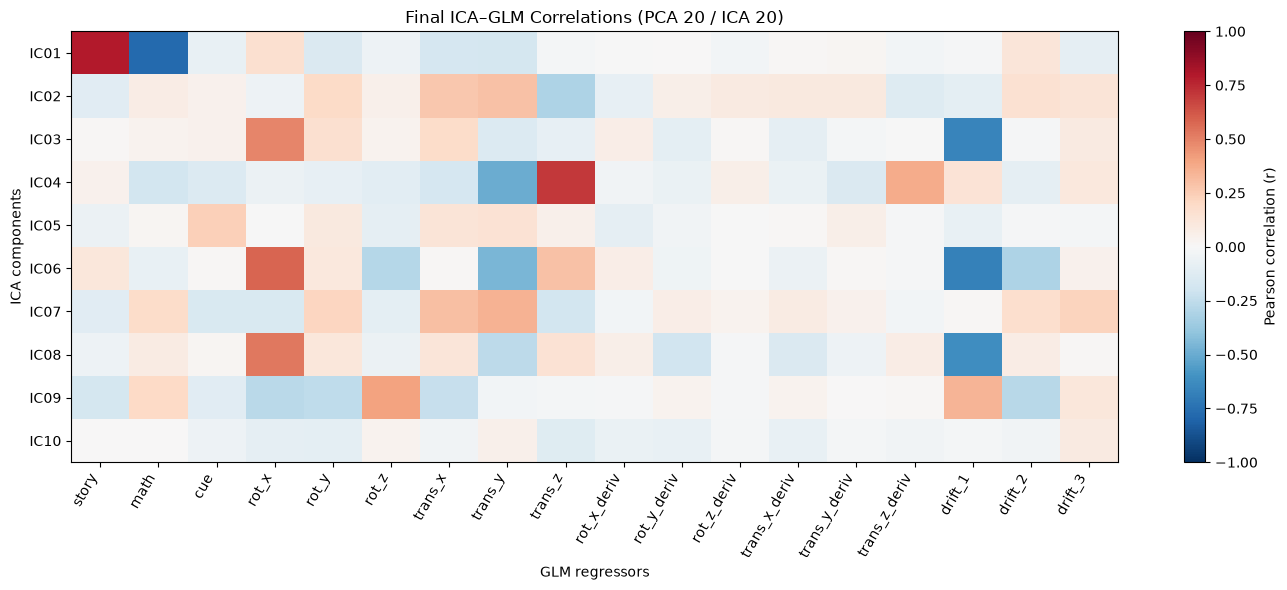


Final task correlations:
      story   math    cue
IC01  0.790 -0.774 -0.075
IC02 -0.114  0.078  0.046
IC03  0.011  0.032  0.043
IC04  0.044 -0.181 -0.136
IC05 -0.060  0.018  0.241
IC06  0.110 -0.075  0.009
IC07 -0.116  0.181 -0.150
IC08 -0.049  0.079  0.022
IC09 -0.177  0.196 -0.112
IC10  0.002  0.007 -0.053


In [25]:
# Final ICA configuration: PCA = 20, ICA = 20
final_timecourses = ica_tc_validated

# Save all 20 validated timecourses
final_tc_df = pd.DataFrame(
    final_timecourses,
    columns=[f"IC{i+1:02d}" for i in range(20)]
)

final_tc_df.to_csv(
    ICA_DIR / "final_ica_timecourses.csv",
    index=False
)

# First 10 components, preserving original ICA order
first_10 = final_tc_df.iloc[:, :10]

# Combine ICA timecourses with GLM regressors
combined = pd.concat(
    [
        first_10.reset_index(drop=True),
        glm_design[selected_regressors].reset_index(drop=True)
    ],
    axis=1
)

# Pearson correlation matrix
final_corr = combined.corr().loc[
    first_10.columns,
    selected_regressors
]

# Save correlation matrix
final_corr.to_csv(
    ICA_DIR / "final_ica_glm_correlations.csv"
)

# Plot heatmap
fig, ax = plt.subplots(figsize=(14, 6))

im = ax.imshow(
    final_corr.values,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(np.arange(len(final_corr.columns)))
ax.set_xticklabels(
    final_corr.columns,
    rotation=60,
    ha="right"
)

ax.set_yticks(np.arange(10))
ax.set_yticklabels(final_corr.index)

ax.set_title(
    "Final ICA–GLM Correlations (PCA 20 / ICA 20)"
)
ax.set_xlabel("GLM regressors")
ax.set_ylabel("ICA components")

fig.colorbar(im, ax=ax, label="Pearson correlation (r)")

plt.tight_layout()

fig.savefig(
    ICA_DIR / "fig_final_ica_glm_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFinal task correlations:")
print(final_corr[["story", "math", "cue"]].round(3))

In [26]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import FastICA

def fit_spatial_ica(n_dim, seed, tol=1e-3, max_iter=1000):
    """Spatial ICA on the first n_dim PCA spatial patterns (N_PCA = N_ICA = n_dim)."""
    model = FastICA(n_components=n_dim, whiten="unit-variance", algorithm="parallel",
                    random_state=seed, max_iter=max_iter, tol=tol)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)   # convergence recorded below
        maps = model.fit_transform(pca.components_[:n_dim].T)
    converged = model.n_iter_ < max_iter
    return model, maps, converged

def component_stability(n_dim, seeds=(0, 1, 2, 3, 4), ref_seed=42):
    """Median |spatial r| of each reference component with its best match across seeds."""
    _, ref, ref_conv = fit_spatial_ica(n_dim, ref_seed)
    matches, n_conv = [], int(ref_conv)
    for s in seeds:
        _, maps, conv = fit_spatial_ica(n_dim, s)
        n_conv += int(conv)
        C = np.abs(np.corrcoef(ref.T, maps.T)[:n_dim, n_dim:])
        rows, cols = linear_sum_assignment(-C)                 # one-to-one matching
        matches.append(C[rows, cols])
    return np.median(matches, axis=0), n_conv, len(seeds) + 1

stability_rows = []
for k in [10, 15, 20, 25, 30]:
    stab, n_conv, n_runs = component_stability(k)
    stability_rows.append({
        "Dimension (PCA = ICA)": k,
        "PCA variance (%)": round(cumulative_variance[k - 1] * 100, 1),
        "Median stability |r|": round(float(np.median(stab)), 3),
        "Stable components (|r| > 0.9)": f"{int((stab > 0.9).sum())}/{k}",
        "Converged runs": f"{n_conv}/{n_runs}",
    })
    print(f"k = {k} done")

stability_table = pd.DataFrame(stability_rows)
stability_table.to_csv(ICA_DIR / "ica_model_order_stability.csv", index=False)
show_table(stability_table)

k = 10 done
k = 15 done
k = 20 done
k = 25 done
k = 30 done


,Dimension (PCA = ICA),PCA variance (%),Median stability |r|,Stable components (|r| > 0.9),Converged runs
0,10,36.700001,0.982,7/10,5/6
1,15,41.200001,0.986,11/15,6/6
2,20,44.500000,0.981,14/20,5/6
3,25,47.000000,0.974,19/25,6/6
4,30,49.000000,0.997,29/30,6/6


### PCA–ICA Dimensionality Selection

We compare 15 combinations of PCA dimensions (10, 15, 20, 25, 30) and ICA components, ensuring that the number of ICA components does not exceed the retained PCA dimensionality.

For each configuration, FastICA is fitted using six random initializations. Component stability is assessed by matching spatial maps across runs using absolute Pearson correlations and optimal one-to-one assignment.

Model selection is based on convergence, spatial reproducibility, and parsimony, independently of the GLM task regressors.

In [27]:
from sklearn.decomposition import FastICA
from scipy.optimize import linear_sum_assignment
from threadpoolctl import threadpool_limits
from IPython.display import display as show_table

import numpy as np
import pandas as pd
import warnings
import time

# ============================================================
# 1. PARAMETERS
# ============================================================

PCA_OPTIONS = [10, 15, 20, 25, 30]
ICA_OPTIONS = [10, 15, 20, 25, 30]

SEEDS = [0, 1, 7, 21, 42, 99]
REFERENCE_SEED = 42

MAX_ITER = 2000
TOL = 1e-4

# Use a separate file to avoid mixing previous experiments
SAVE_PATH = ICA_DIR / "pca_ica_stability_comparison_v2.csv"

ICA_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. LOAD PREVIOUS RESULTS IF AVAILABLE
# ============================================================

if SAVE_PATH.exists():

    previous_df = pd.read_csv(SAVE_PATH)

    results = previous_df.to_dict("records")

    completed = set(
        zip(previous_df["N_PCA"], previous_df["N_ICA"])
    )

    print(f"Loaded {len(completed)} completed configurations.")

else:

    results = []
    completed = set()

stability_details = {}

# ============================================================
# 3. HELPER FUNCTION: SPATIAL CORRELATIONS
# ============================================================

def spatial_correlation_matrix(ref_maps, test_maps):

    # Center component maps
    A = ref_maps - ref_maps.mean(axis=0, keepdims=True)
    B = test_maps - test_maps.mean(axis=0, keepdims=True)

    # Normalize each component
    A_norm = np.linalg.norm(A, axis=0)
    B_norm = np.linalg.norm(B, axis=0)

    if np.any(A_norm == 0) or np.any(B_norm == 0):
        raise ValueError("A spatial component has zero variance.")

    A = A / A_norm
    B = B / B_norm

    # Spatial Pearson correlations
    return np.abs(A.T @ B)


# ============================================================
# 4. COMPARE PCA–ICA CONFIGURATIONS
# ============================================================

for n_pca in PCA_OPTIONS:

    spatial_input = np.asarray(
        pca.components_[:n_pca].T,
        dtype=np.float64
    ).copy()

    if not np.isfinite(spatial_input).all():
        raise ValueError(
            f"PCA input contains NaN or Inf for N_PCA={n_pca}"
        )

    for n_ica in ICA_OPTIONS:

        if n_ica > n_pca:
            continue

        if (n_pca, n_ica) in completed:
            print(
                f"Skipping PCA={n_pca}, ICA={n_ica} "
                "(already completed)"
            )
            continue

        print("\n" + "=" * 55, flush=True)
        print(
            f"Testing PCA={n_pca}, ICA={n_ica}",
            flush=True
        )
        print("=" * 55, flush=True)

        start_config = time.perf_counter()

        # Reference first
        ordered_seeds = [REFERENCE_SEED] + [
            s for s in SEEDS if s != REFERENCE_SEED
        ]

        reference_maps = None
        convergence = {}
        matched_stabilities = []

        # ----------------------------------------------------
        # Fit ICA for each seed
        # ----------------------------------------------------

        for seed in ordered_seeds:

            print(f"  Running seed={seed} ...", flush=True)

            start_seed = time.perf_counter()

            model = FastICA(
                n_components=n_ica,
                whiten="unit-variance",
                algorithm="parallel",
                random_state=seed,
                max_iter=MAX_ITER,
                tol=TOL
            )

            try:

                # Limit numerical library threads
                # to reduce oversubscription
                with threadpool_limits(limits=2):

                    with warnings.catch_warnings(record=True) as caught:

                        warnings.simplefilter("always")

                        maps = model.fit_transform(
                            spatial_input
                        )

                converged = (
                    model.n_iter_ < MAX_ITER
                    and np.isfinite(maps).all()
                    and np.isfinite(model.mixing_).all()
                )

                convergence[seed] = converged

                elapsed = time.perf_counter() - start_seed

                print(
                    f"  Seed {seed}: "
                    f"iterations={model.n_iter_}, "
                    f"converged={converged}, "
                    f"time={elapsed:.1f}s",
                    flush=True
                )

                if converged:

                    if seed == REFERENCE_SEED:

                        reference_maps = maps.copy()

                    elif reference_maps is not None:

                        # Correlate all component maps
                        corr = spatial_correlation_matrix(
                            reference_maps,
                            maps
                        )

                        if np.isfinite(corr).all():

                            # One-to-one component matching
                            rows, cols = linear_sum_assignment(
                                -corr
                            )

                            matched = np.empty(n_ica)
                            matched[rows] = corr[rows, cols]

                            matched_stabilities.append(
                                matched
                            )

                # Display important warnings
                for w in caught:

                    if "converge" in str(w.message).lower():
                        print(
                            f"    Warning: {w.message}",
                            flush=True
                        )

            except (
                ValueError,
                FloatingPointError,
                np.linalg.LinAlgError,
                RuntimeError
            ) as e:

                convergence[seed] = False

                print(
                    f"  Seed {seed}: FAILED "
                    f"({type(e).__name__}: {e})",
                    flush=True
                )

        # ====================================================
        # 5. EVALUATE STABILITY
        # ====================================================

        n_converged = sum(convergence.values())

        n_comparisons = len(matched_stabilities)

        component_stability = None
        median_stability = np.nan
        stable_count = np.nan
        stable_percent = np.nan

        if n_comparisons > 0:

            matched_stabilities = np.asarray(
                matched_stabilities
            )

            # Median across successful seeds
            component_stability = np.median(
                matched_stabilities,
                axis=0
            )

            # Overall stability
            median_stability = float(
                np.median(component_stability)
            )

            # Count stable components
            stable_count = int(
                np.sum(component_stability > 0.9)
            )

            stable_percent = (
                100 * stable_count / n_ica
            )

        # ====================================================
        # 6. STORE RESULTS
        # ====================================================

        results.append({

            "N_PCA": n_pca,
            "N_ICA": n_ica,

            "PCA variance (%)": float(
                cumulative_variance[n_pca - 1] * 100
            ),

            "Median stability |r|": median_stability,

            "Stable components": stable_count,

            "Stable (%)": stable_percent,

            "Converged runs": (
                f"{n_converged}/{len(SEEDS)}"
            ),

            "Stability comparisons": n_comparisons
        })

        stability_details[(n_pca, n_ica)] = {
            "component_stability": component_stability,
            "convergence": convergence
        }

        # ====================================================
        # 7. SAVE AFTER EACH CONFIGURATION
        # ====================================================

        dimension_comparison_df = pd.DataFrame(results)

        dimension_comparison_df.to_csv(
            SAVE_PATH,
            index=False
        )

        completed.add((n_pca, n_ica))

        elapsed_config = (
            time.perf_counter() - start_config
        )

        print(
            f"\n  Finished PCA={n_pca}, ICA={n_ica}",
            flush=True
        )

        print(
            f"  Convergence: {n_converged}/{len(SEEDS)}",
            flush=True
        )

        print(
            f"  Median stability: {median_stability:.3f}",
            flush=True
        )

        print(
            f"  Stable components: {stable_count}/{n_ica}",
            flush=True
        )

        print(
            f"  Stability comparisons: {n_comparisons}",
            flush=True
        )

        print(
            f"  Total time: {elapsed_config:.1f}s",
            flush=True
        )

        print(
            f"  Results saved to: {SAVE_PATH.name}",
            flush=True
        )

# ============================================================
# 8. FINAL RESULTS TABLE
# ============================================================

dimension_comparison_df = pd.DataFrame(results)

dimension_comparison_df = (
    dimension_comparison_df
    .sort_values(["N_PCA", "N_ICA"])
    .reset_index(drop=True)
)

print("\nFINAL PCA–ICA STABILITY COMPARISON\n")

show_table(dimension_comparison_df.round(3))

print(
    f"\nSaved: {SAVE_PATH}"
)


Testing PCA=10, ICA=10
  Running seed=42 ...
  Seed 42: iterations=135, converged=True, time=1.7s
  Running seed=0 ...
  Seed 0: iterations=315, converged=True, time=3.9s
  Running seed=1 ...
  Seed 1: iterations=1087, converged=True, time=13.1s
  Running seed=7 ...
  Seed 7: iterations=395, converged=True, time=4.7s
  Running seed=21 ...
  Seed 21: iterations=187, converged=True, time=2.3s
  Running seed=99 ...
  Seed 99: iterations=1105, converged=True, time=13.1s

  Finished PCA=10, ICA=10
  Convergence: 6/6
  Median stability: 1.000
  Stable components: 10/10
  Stability comparisons: 5
  Total time: 39.0s
  Results saved to: pca_ica_stability_comparison_v2.csv

Testing PCA=15, ICA=10
  Running seed=42 ...
  Seed 42: iterations=22, converged=True, time=0.5s
  Running seed=0 ...
  Seed 0: iterations=30, converged=True, time=0.5s
  Running seed=1 ...
  Seed 1: iterations=19, converged=True, time=0.4s
  Running seed=7 ...
  Seed 7: iterations=25, converged=True, time=0.5s
  Running se

,N_PCA,N_ICA,PCA variance (%),Median stability |r|,Stable components,Stable (%),Converged runs,Stability comparisons
0,10,10,36.679,1.000,10.0,100.000,6/6,5
1,15,10,41.227,1.000,10.0,100.000,6/6,5
2,15,15,41.227,1.000,15.0,100.000,6/6,5
3,20,10,44.541,NaN,NaN,NaN,1/6,0
4,20,15,44.541,NaN,NaN,NaN,0/6,0
5,20,20,44.541,0.992,17.0,85.000,6/6,5
6,25,10,47.013,NaN,NaN,NaN,0/6,0
7,25,15,47.013,NaN,NaN,NaN,0/6,0
8,25,20,47.013,NaN,NaN,NaN,0/6,0
9,25,25,47.013,0.986,21.0,84.000,6/6,5



Saved: /data/Desktop/myfiles/NX421-MiniProject-1/outputs/ica/pca_ica_stability_comparison_v2.csv


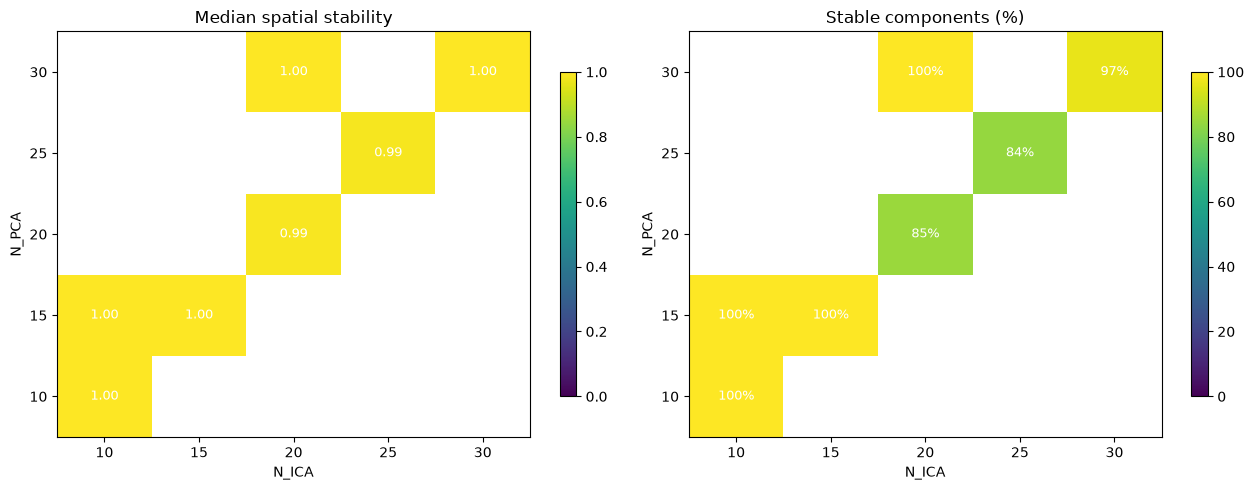

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics = [
    ("Median stability |r|", "Median spatial stability"),
    ("Stable (%)", "Stable components (%)")
]

for ax, (metric, title) in zip(axes, metrics):

    matrix = dimension_comparison_df.pivot(
        index="N_PCA",
        columns="N_ICA",
        values=metric
    )

    values = np.ma.masked_invalid(matrix.values)

    im = ax.imshow(
        values,
        cmap="viridis",
        origin="lower",
        aspect="auto",
        vmin=0 if metric == "Stable (%)" else 0,
        vmax=100 if metric == "Stable (%)" else 1
    )

    ax.set_xticks(range(len(matrix.columns)))
    ax.set_xticklabels(matrix.columns)

    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(matrix.index)

    ax.set_xlabel("N_ICA")
    ax.set_ylabel("N_PCA")
    ax.set_title(title)

    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            value = matrix.iloc[i, j]

            if np.isfinite(value):
                ax.text(
                    j, i, f"{value:.2f}" if metric != "Stable (%)"
                    else f"{value:.0f}%",
                    ha="center",
                    va="center",
                    color="white",
                    fontsize=9
                )

    fig.colorbar(im, ax=ax, shrink=0.8)

plt.tight_layout()

plt.savefig(
    ICA_DIR / "fig_pca_ica_stability_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
N_FINAL = 15        # selected: elbow + 100 % stable components + 6/6 convergence
SEED = 42           # fixed a priori
TOL = 1e-4

final_model = FastICA(n_components=N_FINAL, whiten="unit-variance", algorithm="parallel",
                      random_state=SEED, max_iter=5000, tol=TOL)
final_maps = final_model.fit_transform(pca.components_[:N_FINAL].T)   # (voxels, 15)
final_tc = X_pca[:, :N_FINAL] @ final_model.mixing_                  # (316, 15)
print("Iterations:", final_model.n_iter_, "| converged:", final_model.n_iter_ < 5000)

# Sign convention: the largest absolute spatial weight of each component is positive
peak_signs = np.sign(final_maps[np.abs(final_maps).argmax(axis=0), np.arange(N_FINAL)])
final_maps = final_maps * peak_signs
final_tc = final_tc * peak_signs

ic_names = [f"IC{i+1:02d}" for i in range(N_FINAL)]
pd.DataFrame(final_tc, columns=ic_names).to_csv(ICA_DIR / "final_ica_timecourses.csv", index=False)

Iterations: 86 | converged: True


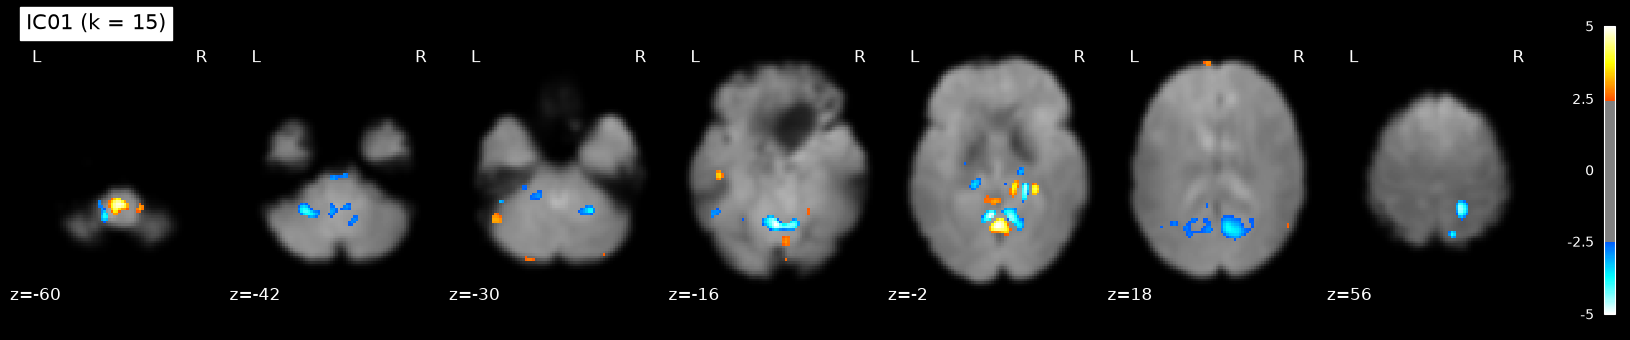

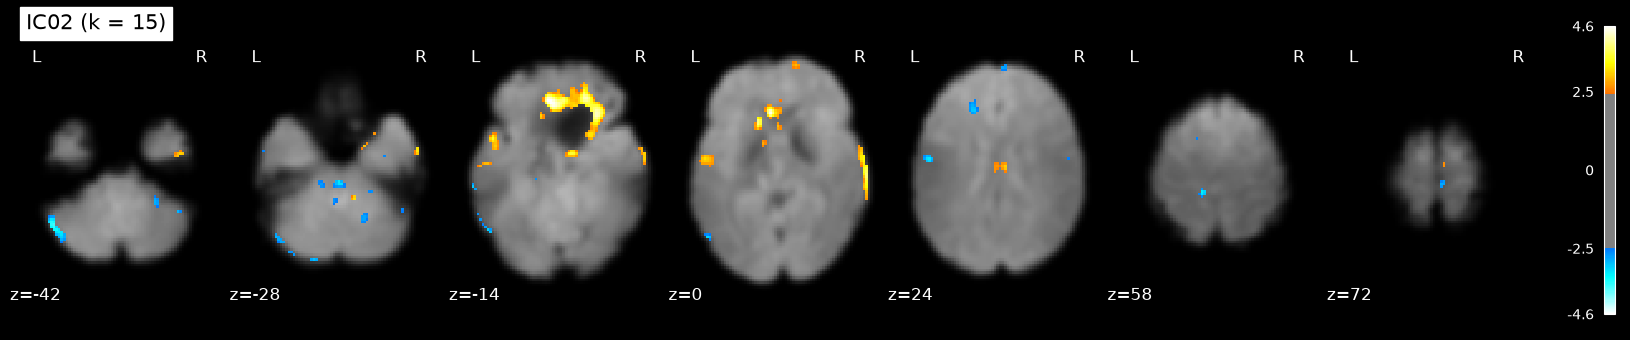

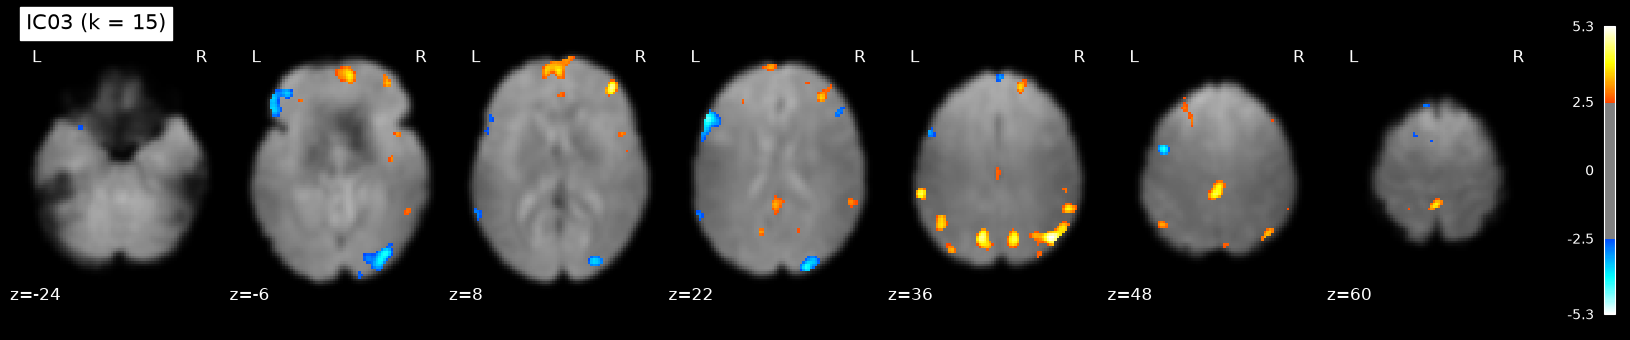

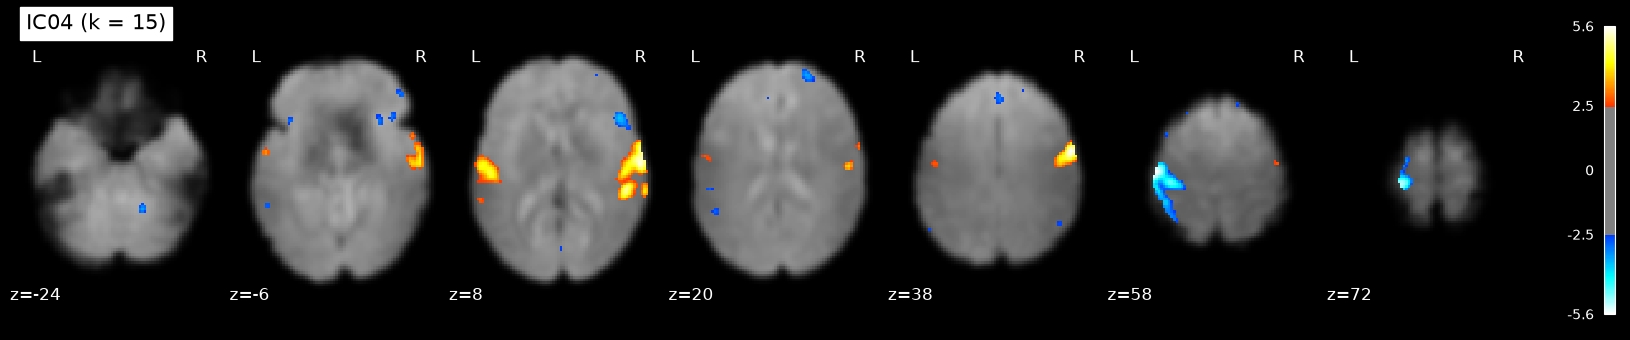

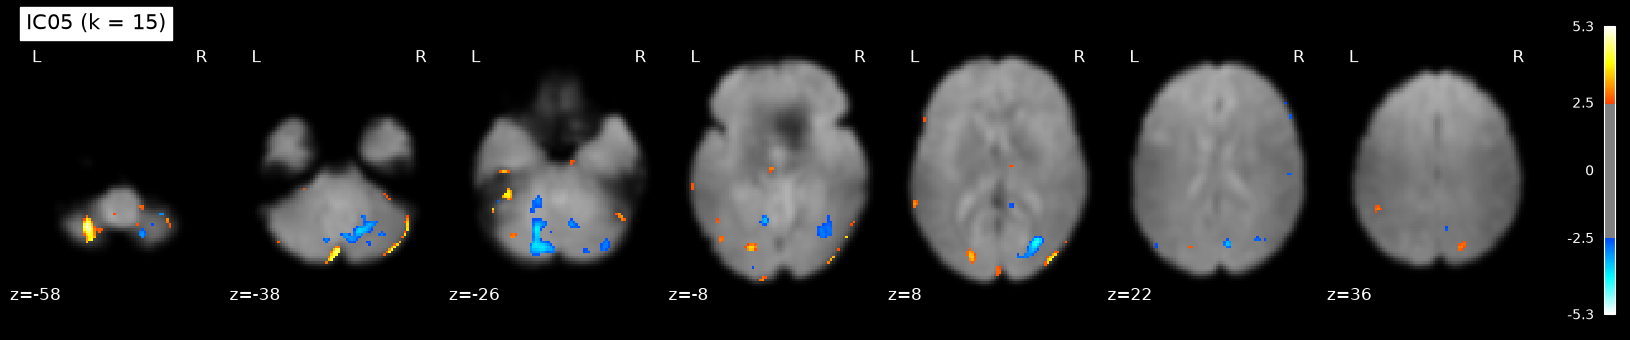

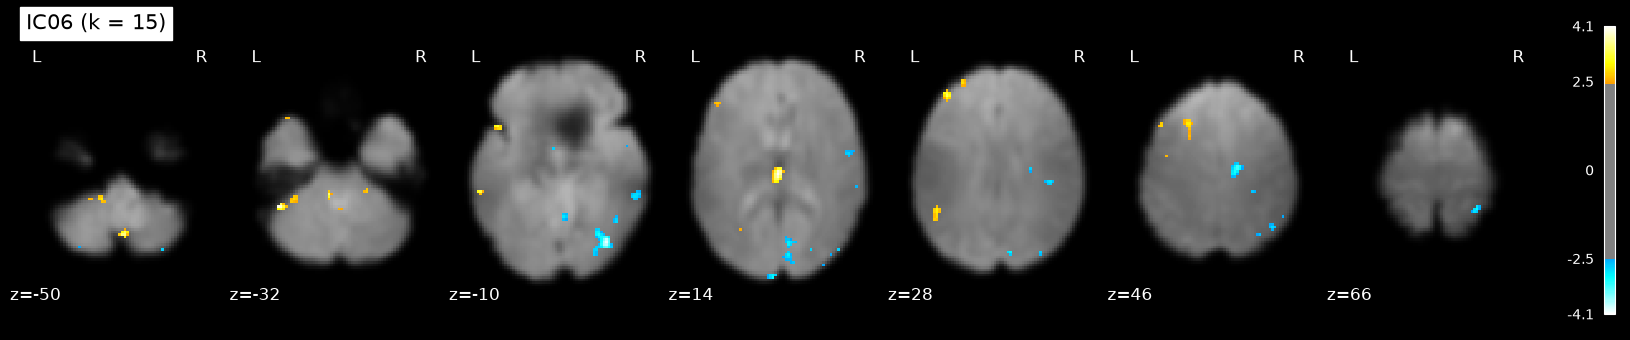

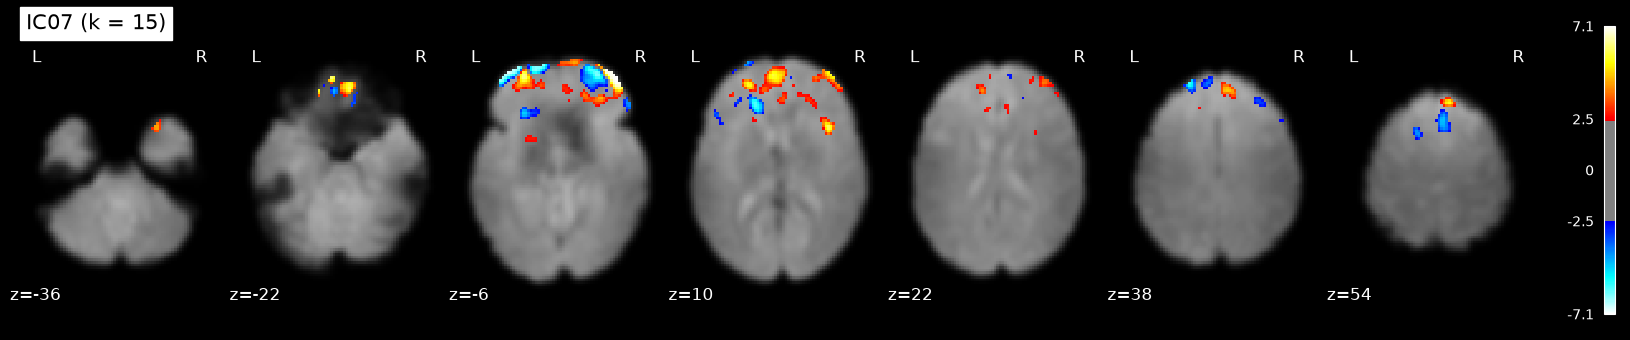

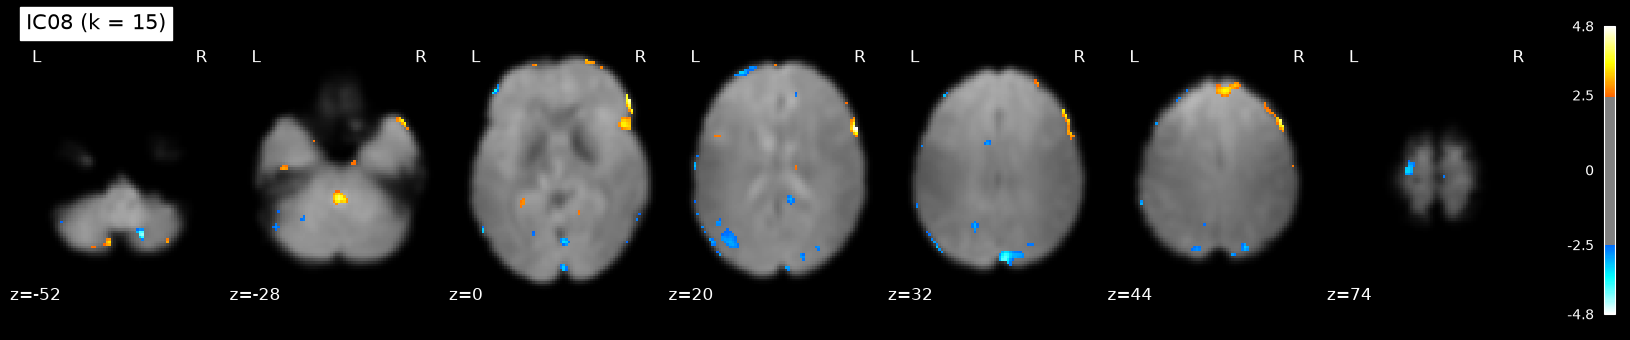

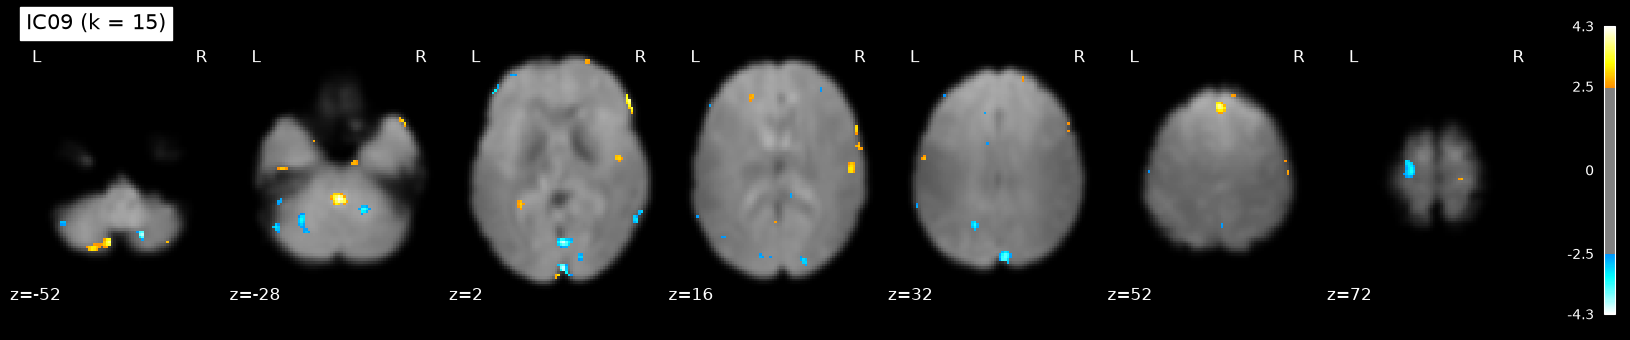

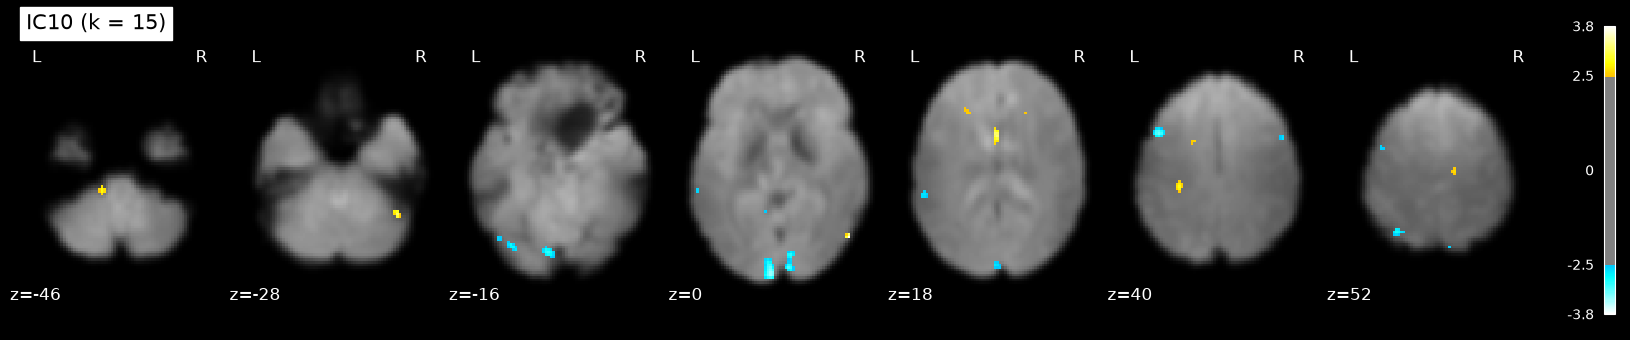

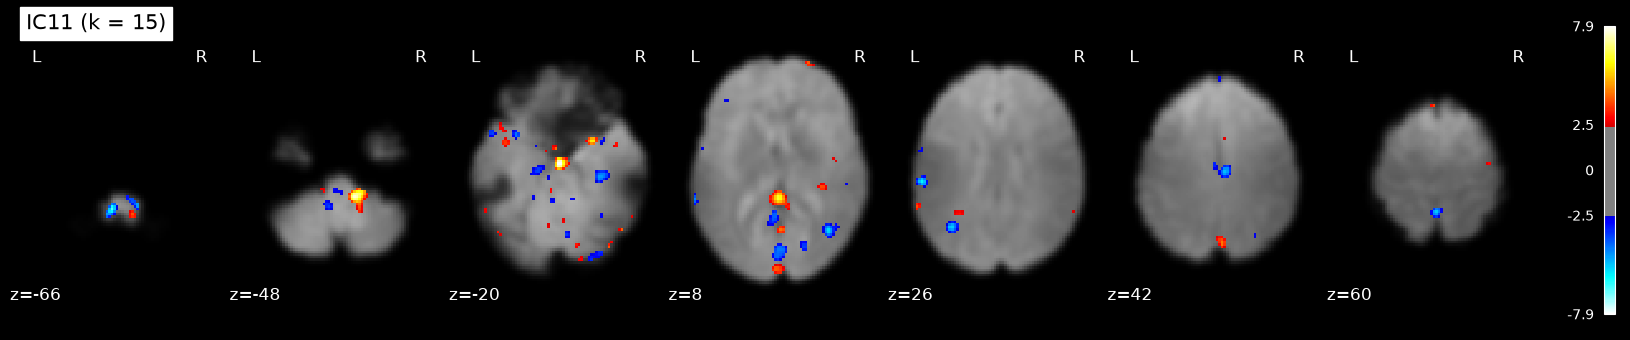

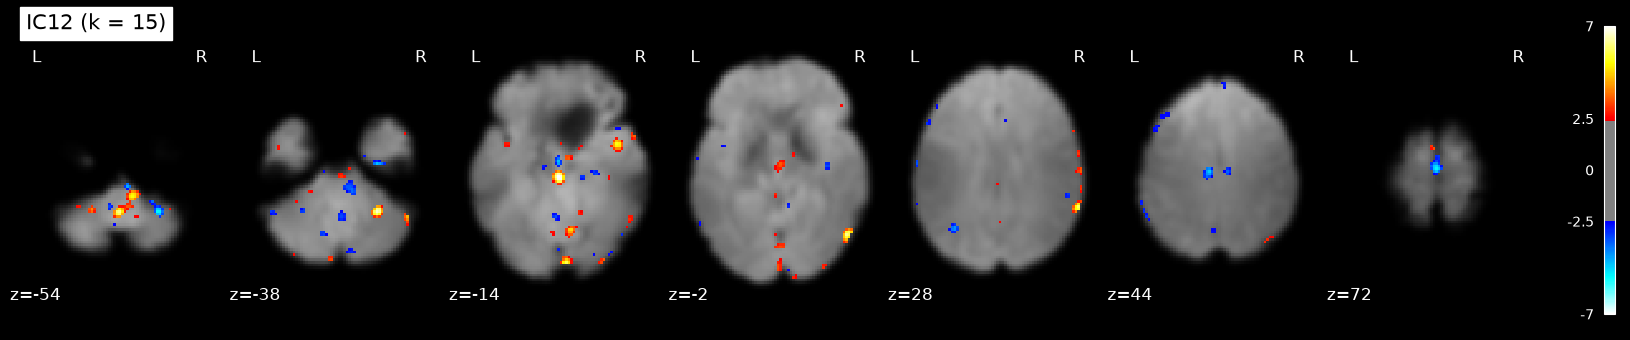

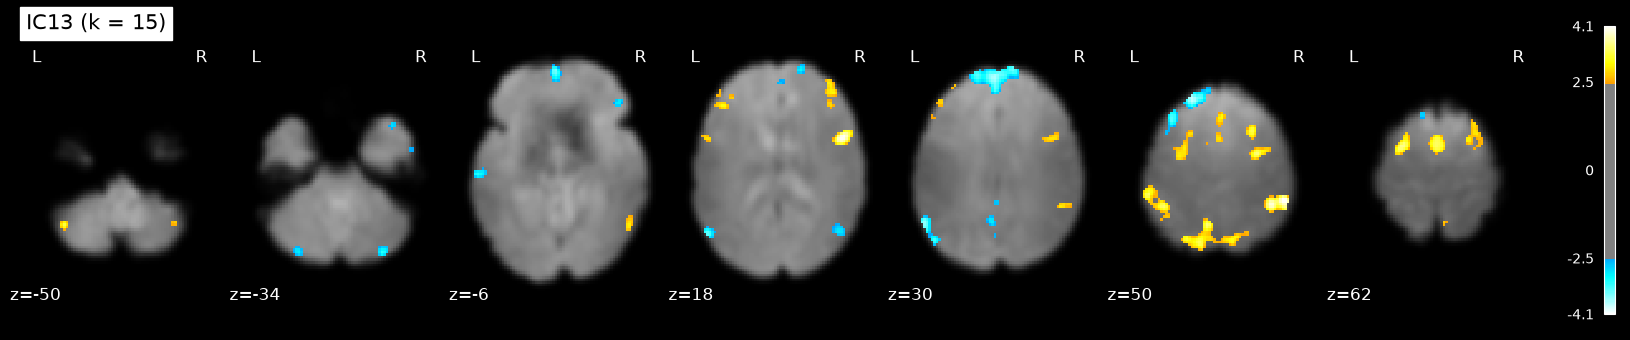

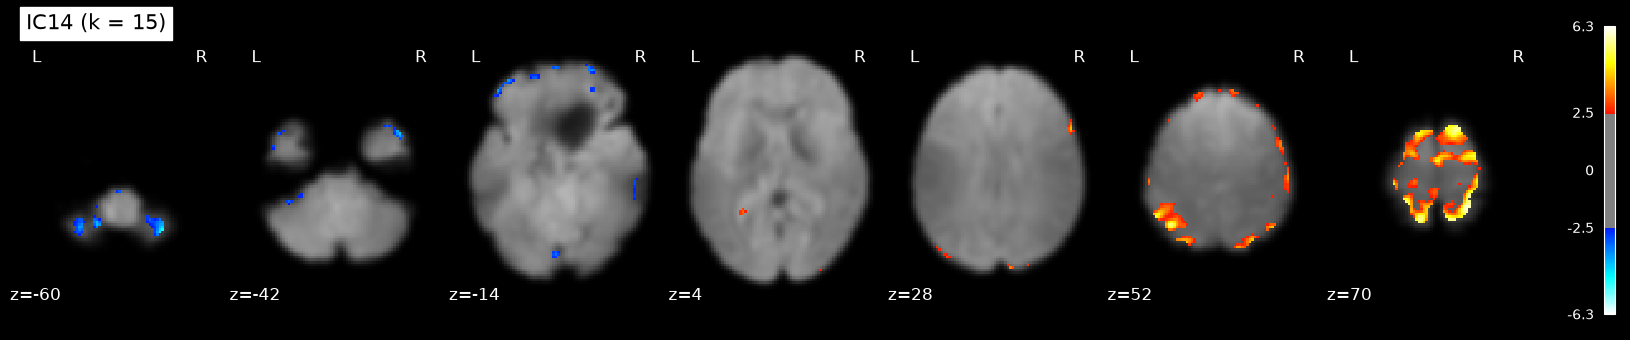

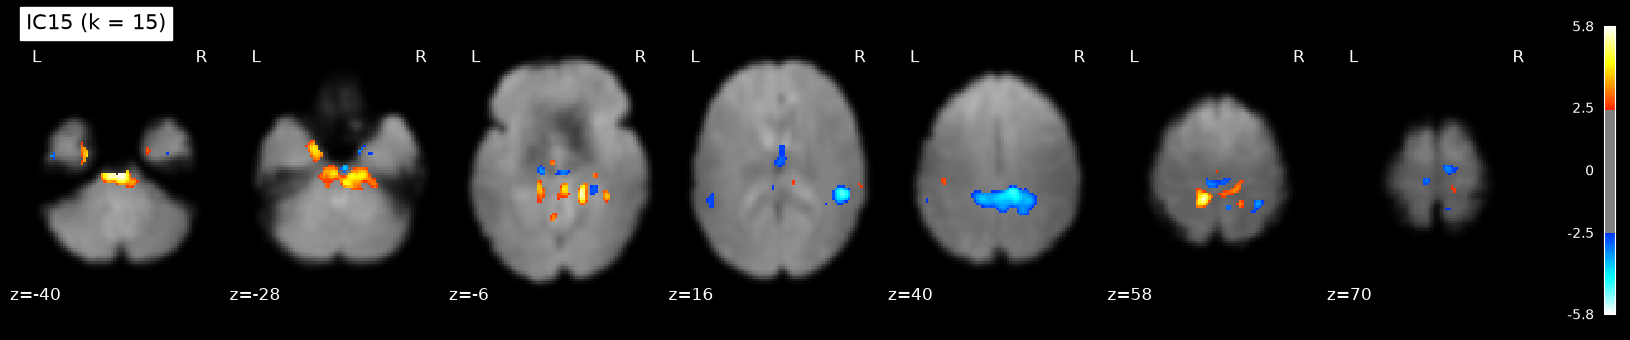

In [31]:
import os
mni_bg = Path(os.environ.get("FSLDIR", "")) / "data" / "standard" / "MNI152_T1_2mm_brain.nii.gz"
bg_img = str(mni_bg) if mni_bg.is_file() else image.mean_img(fmri_img)

final_fig_dir = ICA_DIR / "figures_final"
final_fig_dir.mkdir(parents=True, exist_ok=True)

for i in range(N_FINAL):
    z = (final_maps[:, i] - final_maps[:, i].mean()) / final_maps[:, i].std()
    comp_img = masking.unmask(z, mask_img)
    comp_img.to_filename(str(ICA_DIR / f"final_ic_{i+1:02d}.nii.gz"))
    disp = plotting.plot_stat_map(comp_img, bg_img=bg_img, display_mode="z",
                                  cut_coords=7, threshold=2.5, cmap="cold_hot",
                                  colorbar=True, title=f"IC{i+1:02d} (k = {N_FINAL})")
    disp.savefig(str(final_fig_dir / f"ic_{i+1:02d}.png"), dpi=200)
    plotting.show()

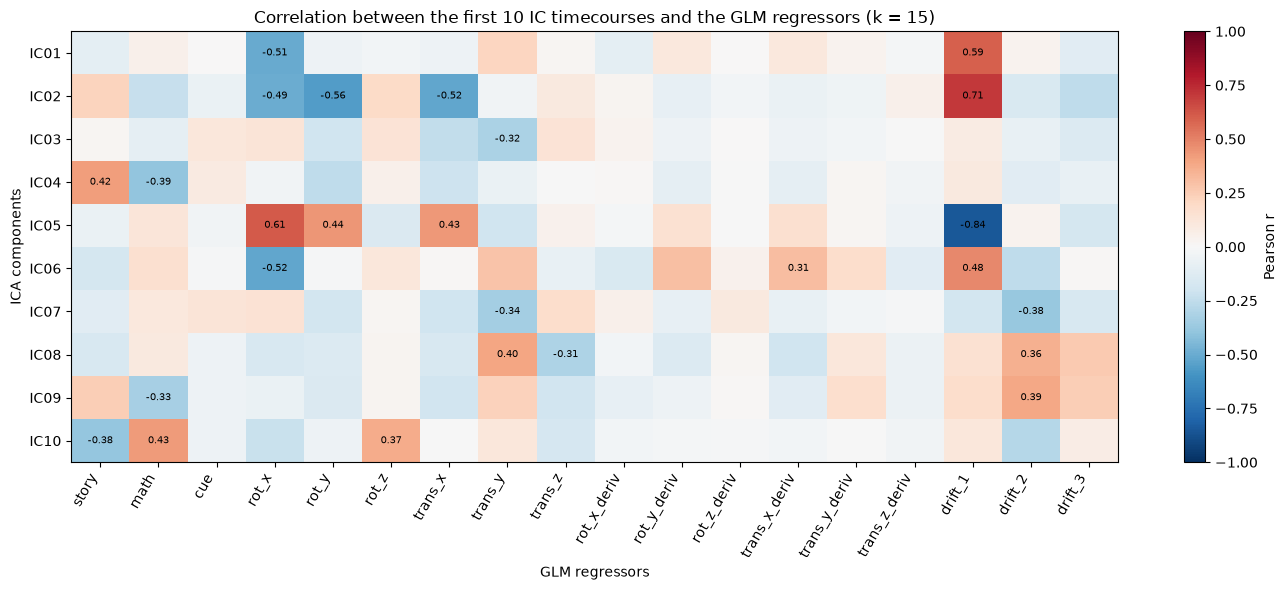

In [34]:
first10 = pd.DataFrame(final_tc[:, :10], columns=ic_names[:10])
final_corr = pd.concat(
    [first10.reset_index(drop=True),
     glm_design[selected_regressors].reset_index(drop=True)],
    axis=1
).corr().loc[ic_names[:10], selected_regressors]
final_corr.to_csv(ICA_DIR / "final_ica_glm_correlations.csv")

fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(final_corr.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
for i in range(final_corr.shape[0]):
    for j in range(final_corr.shape[1]):
        if abs(final_corr.iloc[i, j]) >= 0.3:
            ax.text(j, i, f"{final_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(len(selected_regressors)))
ax.set_xticklabels(selected_regressors, rotation=60, ha="right")
ax.set_yticks(range(10))
ax.set_yticklabels(ic_names[:10])
ax.set(title=f"Correlation between the first 10 IC timecourses and the GLM regressors (k = {N_FINAL})",
       xlabel="GLM regressors", ylabel="ICA components")
fig.colorbar(im, ax=ax, label="Pearson r")
plt.tight_layout()
fig.savefig(ICA_DIR / "fig_final_ica_glm_correlations.png", dpi=300, bbox_inches="tight")
plt.show()

In [35]:
from scipy.ndimage import binary_erosion

glm_z_values = masking.apply_mask(glm_z_img, mask_img)          # unthresholded story−math Z
edge_vox = (mask_data & ~binary_erosion(mask_data, iterations=2))[mask_data]
motion_cols = [c for c in selected_regressors if c.startswith(("rot_", "trans_"))]

rows = []
for i in range(10):
    tc, m = final_tc[:, i], final_maps[:, i]
    z = (m - m.mean()) / m.std()
    r = lambda col: np.corrcoef(tc, glm_design[col])[0, 1]
    rows.append({"IC": ic_names[i],
                 "r story": r("story"), "r math": r("math"), "r cue": r("cue"),
                 "max |r| motion": max(abs(r(c)) for c in motion_cols),
                 "r drift_1": r("drift_1"),
                 "spatial r with GLM": np.corrcoef(m, glm_z_values)[0, 1],
                 "% |z|>2.5 at edge": 100 * (np.abs(z) > 2.5)[edge_vox].sum() / max((np.abs(z) > 2.5).sum(), 1)})
ic_summary = pd.DataFrame(rows).set_index("IC").round(2)
ic_summary.to_csv(ICA_DIR / "final_ica_component_summary.csv")
print(f"Edge voxels: {100 * edge_vox.mean():.1f}% of the mask")
show_table(ic_summary)

Edge voxels: 15.0% of the mask


,r story,r math,r cue,max |r| motion,r drift_1,spatial r with GLM,% |z|>2.5 at edge
IC,,,,,,,
IC01,-0.10,0.05,0.00,0.51,0.59,-0.13,8.47
IC02,0.22,-0.23,-0.06,0.56,0.71,0.09,35.96
IC03,0.02,-0.09,0.12,0.32,0.08,-0.02,21.17
IC04,0.42,-0.39,0.09,0.26,0.10,0.27,28.61
IC05,-0.06,0.12,-0.03,0.61,-0.84,-0.03,28.39
IC06,-0.18,0.16,-0.01,0.52,0.48,-0.06,23.72
IC07,-0.12,0.11,0.13,0.34,-0.19,-0.12,28.36
IC08,-0.16,0.10,-0.05,0.40,0.15,0.03,52.84
IC09,0.24,-0.33,-0.05,0.23,0.18,0.19,41.07


In [36]:
from nilearn import signal

# Same temporal preprocessing as the GLM: linear detrending + high-pass (1/128 Hz),
# then z-scoring of each voxel time series
X_standardized = signal.clean(
    X, detrend=True, high_pass=1/128, t_r=tr,
    standardize="zscore_sample"     # use standardize=True if this option is not accepted
).astype(np.float32)

print("Shape:", X_standardized.shape,
      "| mean:", round(float(X_standardized.mean()), 4),
      "| std:", round(float(X_standardized.std()), 4))

Shape: (316, 207772) | mean: -0.0 | std: 0.9984


## 6. Results and Interpretation

### 6.1 Selection of PCA and ICA Dimensions

We evaluated nine configurations combining 20, 40, and 60 PCA dimensions with 10, 15, and 20 ICA components.

The PCA = 20, ICA = 20 configuration was selected as an exploratory final model based on convergence, task-related correlations, and subsequent validation of its most task-associated component.

This configuration retained 44.54% of the total variance and converged after 20 iterations. Importantly, the selection was informed by task correlations and therefore should not be considered an entirely independent, unsupervised model-selection procedure.

### 6.2 Task-Related ICA Component

IC01 showed strong temporal correlations with the GLM task regressors:

- Story: **r = +0.790**
- Math: **r = −0.774**
- Cue: **r = −0.075**

The opposite Story and Math correlations are consistent with their strongly anticorrelated experimental regressors.

IC01 also showed strong spatial agreement with the unthresholded GLM Story − Math contrast (**r = +0.803**, across 207,772 brain-mask voxels).

These findings suggest that IC01 captures a spatial and temporal pattern associated with the Story–Math task distinction.

### 6.3 Component Stability

IC01 was recovered across five ICA random seeds, with a mean absolute spatial correlation of approximately **0.993** relative to the reference map. All five models converged.

This indicates high reproducibility of IC01 across the tested random initializations, although it does not establish the stability of the other 19 components.

### 6.4 Limitations

This analysis uses data from a single subject and one fMRI run. The ICA–GLM spatial agreement is descriptive because both analyses were performed on the same data. ICA component signs and ordering are arbitrary, and some spatial maps contain scattered or boundary-associated patterns that may reflect noise or artifacts.

Consequently, IC01 is interpreted as a **task-associated component**, rather than definitively identified as a specific language network.